Further files with the same prefix means progress. This ones has less extra cells. Only what is needed.

In [63]:
import pandas as pd
import numpy as np
from math import sqrt, pi, exp
from arch import arch_model
import yfinance as yf 
from scipy.optimize import minimize
import warnings
from arch.__future__ import reindexing
from arch.utility.exceptions import ConvergenceWarning
# from srcA.msGarch import msGARCH
# from srcA.metrics import metrics
# from srcA.msGarch import msGARCHIV
from tqdm import tqdm

from xgboost import XGBRegressor
warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", message="y is poorly scaled")
warnings.filterwarnings("ignore", category=RuntimeWarning)
warnings.filterwarnings("ignore", category=ConvergenceWarning)


In [64]:

import os, sys
sys.path.insert(0, "/Users/shah/CODE_BOOK_4/THESIS_WORKING/THESIS_2")
os.chdir("/Users/shah/CODE_BOOK_4/THESIS_WORKING/THESIS_2")
sys.modules.pop("srcA", None)


<module 'srcA' (namespace) from ['/Users/shah/CODE_BOOK_4/code_document/REPOSITORIES/MFIV_calibration/srcA']>

In [65]:

import sys, os
sys.path.insert(0, "/Users/shah/CODE_BOOK_4/code_document/REPOSITORIES/MFIV_calibration")
from srcA.models_MFIV import estimate_naive10_mfiv, estimate_garch_mfiv

### outputs

In [66]:
# Load NEW from temp_modelling
import pickle 
with open("/Users/shah/CODE_BOOK_4/code_document/REPOSITORIES/data/IS/outputs_by_year/outputs_by_year_05.pkl", "rb") as f:
    outputs_by_year = pickle.load(f)

In [67]:
outputs_by_year[2021]["q1"].columns

Index(['rv', 'rt', 'date_time', 'garch', 'garch_mfiv', 'garch_mfiv_avg',
       'regime_switching_mfiv', 'regime_state', 'selected_horizon', 'MFIV_191',
       'MFIV_382', 'MFIV_573', 'MFIV_764'],
      dtype='str')

### Market

In [6]:
# NON NEGATIVE CASH ! LAT BEST 17 July
 
import pandas as pd
import numpy as np
from scipy.stats import norm
 
 
class Chain:
    def __init__(self):
        self.instruments = []
 
class Instrument:
    def __init__(self, symbol, strike, right, direction, price_per_contract, expiry, option_price_btc):
        self.Symbol = symbol
        self.Strike = strike
        self.Right = right
        self.Direction = direction
        self.Price = price_per_contract
        self.Expiry = expiry
        self.OptionPriceBTC = option_price_btc
 
class Holdings: 
    def __init__(self, cash, now):
        self.time = now
        self.instruments = [] 
        self.cash = cash
        
    def get_cash(self):
        return self.cash
 
    def get_time(self):
        return self.time
        
    def long_instrument(self, instrument):
        self.instruments.append(instrument)
 
    def short_instrument(self, instrument):
        self.instruments.append(instrument)
 
    def close_position(self, key, qty=1):
        # FIX: only remove `qty` matching contracts, not every contract matching the key.
        strike, expiry, right, direction = key
        remaining = []
        removed = 0
        for i in self.instruments:
            if (removed < qty and i.Strike == strike and i.Expiry == expiry
                    and i.Right == right and i.Direction == direction):
                removed += 1
                continue
            remaining.append(i)
        self.instruments = remaining
 
class Market:
    def __init__(self, option_df, time_df, starting_cash=100_000, im_multiplier=0.15, mm_buffer_rate=0.05):
        self.time = time_df.index
        self.option = option_df.copy()
        self.chain = Chain()
        self.option_values = []
        self.time_df = time_df.copy()
        self.spot = None

        # Margin configuration parameters
        self.im_multiplier = im_multiplier    # Standard: 0.10 to 0.15 (10-15%)
        self.mm_buffer_rate = mm_buffer_rate  # Additional market maker buffer standard: 0.05 (5%)
        
        # Live tracking variables
        self.locked_initial_margin = 0.0
        self.locked_buffer_margin = 0.0
                
        self.option["strike"] = self.option["instrument_name"].str.split("-").str[2].astype(float)
        self.option["type"] = self.option["instrument_name"].str.split("-").str[3]
        self.option["maturity"] = pd.to_datetime(
            self.option["instrument_name"].str.split("-").str[1], format="%d%b%y").dt.tz_localize("UTC").dt.floor("h")
        self.option["price_per_contract"] = self.option["price"] * self.option["index_price"]
 
        self.option["date_time"] = pd.to_datetime(self.option["date_time"]).dt.tz_localize("UTC").dt.floor("h")
    
        self.orders = []
        self.transactions = []
        self.starting_cash = starting_cash
        self.cash = starting_cash
        self.equity_history = []
 
        self.now = None
        self.holdings = Holdings(starting_cash, self.now)   
        self.current = pd.DataFrame()

    def calculate_margin_requirements(self):
        # Counts only active short positions to lock margin capital
        short_qty = sum(1 for i in self.holdings.instruments if i.Direction == "sell")
        
        # FIXED: Removed contract_size completely; uses your 100x multiplier scale natively
        self.locked_initial_margin = self.spot * self.im_multiplier * short_qty
        self.locked_buffer_margin = self.spot * self.mm_buffer_rate  * short_qty
        

    def get_total_required_margin(self):
        """Returns the total absolute cash balance that must remain in reserves."""
        return self.locked_initial_margin + self.locked_buffer_margin

    def get_free_liquidity(self):
        """Spendable/usable cash balance remaining after subtracting locked margin reserves."""
        return self.cash - self.get_total_required_margin()

    def update(self, now):
        self.now = pd.Timestamp(now).floor("h")
        self.holdings.time = self.now
        self.current = self.option[self.option["date_time"] == self.now].copy()
        self.spot = self.time_df.loc[self.now, "close"]
        
        # FIXED: Reordered processing sequentially so spot exists before margin math triggers
        self.remove_expired()
        self.calculate_margin_requirements()

        self.chain.instruments = [
            Instrument(
                row["instrument_name"],
                row["strike"],
                row["type"],
                row["direction"],
                row["price_per_contract"],
                row["maturity"],
                row["price"]
            )
            for _, row in self.current.iterrows()
        ]
 
    def remove_expired(self):
        expired_options = [i for i in self.holdings.instruments if i.Expiry <= self.now]
 
        for i in expired_options:
            if i.Right == "C":
                payoff = max(self.spot - i.Strike, 0.0)
            else:
                payoff = max(i.Strike - self.spot, 0.0)
 
            delivery_fee = 0.0
            if payoff > 0:
                base_fee = 0.00015 * self.spot 
                fee_cap = 0.125 * payoff
                delivery_fee = min(base_fee, fee_cap)
                    
            if i.Direction == "buy":
                cash_change = (payoff) - delivery_fee
            else:
                cash_change = -(payoff) - delivery_fee
 
            self.transactions.append({
                "time": self.now,
                "action": "expiry_settlement",
                "symbol": i.Symbol,
                "strike": i.Strike,
                "expiry": i.Expiry,
                "right": i.Right,
                "held_direction": i.Direction,
                "qty": 1,
                "price": payoff,
                "fee": delivery_fee,
                "cash_change": cash_change,
                "cash_before": self.cash,
                "cash_after": self.cash + cash_change,
                "spot": self.spot
            })
 
            self.cash += cash_change
 
        self.holdings.instruments = [i for i in self.holdings.instruments if i.Expiry > self.now]
        self.holdings.cash = self.cash
        self.calculate_margin_requirements()
    
    def buy(self, instrument, qty=1):
        fee = min(0.0003, 0.125 * instrument.OptionPriceBTC) * self.spot * qty
        cash_change = -(instrument.Price * qty + fee)

        if self.get_free_liquidity() + cash_change < 0:
            return None
        # if self.cash + cash_change < 0:
        #     return None

        order = {
            "time": self.now,
            "symbol": instrument.Symbol,
            "strike": instrument.Strike,
            "expiry": instrument.Expiry,
            "right": instrument.Right,
            "spot_entry": self.spot,
            "side": "long",
            "qty": qty,
            "entry_price": instrument.Price
        }
        self.orders.append(order)

        self.transactions.append({
            "time": self.now,
            "action": "buy_to_open",
            "symbol": instrument.Symbol,
            "strike": instrument.Strike,
            "expiry": instrument.Expiry,
            "right": instrument.Right,
            "held_direction": "buy",
            "qty": qty,
            "price": instrument.Price,
            "fee": fee,
            "cash_change": cash_change,
            "cash_before": self.cash,
            "cash_after": self.cash + cash_change,
            "spot": self.spot
        })

        self.cash += cash_change
        self.holdings.cash = self.cash

        for _ in range(qty):
            self.holdings.instruments.append(
                Instrument(
                    instrument.Symbol,
                    instrument.Strike,
                    instrument.Right,
                    "buy",
                    instrument.Price,
                    instrument.Expiry,
                    instrument.OptionPriceBTC
                )
            )

        self.calculate_margin_requirements()
        return order
        
    def sell(self, instrument, qty=1):
        fee = min(0.0003, 0.125 * instrument.OptionPriceBTC) * self.spot * qty
        cash_change = instrument.Price * qty - fee

        new_initial_margin = self.spot * self.im_multiplier * qty
        new_buffer_margin = self.spot * self.mm_buffer_rate * qty

        if (self.cash + cash_change - self.locked_initial_margin - self.locked_buffer_margin - new_initial_margin - new_buffer_margin < 0):
            return None
        
        order = {
            "time": self.now,
            "symbol": instrument.Symbol,
            "strike": instrument.Strike,
            "expiry": instrument.Expiry,
            "right": instrument.Right,
            "spot_entry": self.spot,
            "side": "short",
            "qty": qty,
            "entry_price": instrument.Price
        }
        self.orders.append(order)

        self.transactions.append({
            "time": self.now,
            "action": "sell_to_open",
            "symbol": instrument.Symbol,
            "strike": instrument.Strike,
            "expiry": instrument.Expiry,
            "right": instrument.Right,
            "held_direction": "sell",
            "qty": qty,
            "price": instrument.Price,
            "fee": fee,
            "cash_change": cash_change,
            "cash_before": self.cash,
            "cash_after": self.cash + cash_change,
            "spot": self.spot
        })

        self.cash += cash_change
        self.holdings.cash = self.cash

        for _ in range(qty):
            self.holdings.instruments.append(
                Instrument(
                    instrument.Symbol,
                    instrument.Strike,
                    instrument.Right,
                    "sell",
                    instrument.Price,
                    instrument.Expiry,
                    instrument.OptionPriceBTC
                )
            )

        self.calculate_margin_requirements()
        return order
     
    # def liquidate(self, key, instrument, qty=1):
    #     if instrument.Direction == "buy":
    #         action_name = "sell_to_close"
    #         exec_dir = "sell"
    #     else:
    #         action_name = "buy_to_close"
    #         exec_dir = "buy"
 
    #     current_inst = next((i for i in self.chain.instruments if i.Symbol == instrument.Symbol), None)
    #     current_price = current_inst.Price if current_inst else instrument.Price
    #     opt_price_btc = current_inst.OptionPriceBTC if current_inst else instrument.OptionPriceBTC
 
    #     fee = min(0.0003, 0.125 * opt_price_btc) * self.spot * qty
        
    #     if exec_dir == "sell":
    #         cash_change = (current_price * qty) - fee
    #     else:
    #         cash_change = -(current_price * qty + fee)
 
    #     self.transactions.append({
    #         "time": self.now,
    #         "action": action_name,
    #         "symbol": instrument.Symbol,
    #         "strike": instrument.Strike,
    #         "expiry": instrument.Expiry,
    #         "right": instrument.Right,
    #         "held_direction": instrument.Direction,
    #         "qty": qty,
    #         "price": current_price,
    #         "fee": fee,
    #         "cash_change": cash_change,
    #         "cash_before": self.cash,
    #         "cash_after": self.cash + cash_change,
    #         "spot": self.spot
    #     })
 
    #     self.cash += cash_change
    #     self.holdings.close_position(key, qty)
    #     self.holdings.cash = self.cash
    #     self.calculate_margin_requirements()
    def liquidate(self, key, instrument, qty=1):
        if instrument.Direction == "buy":
            action_name = "sell_to_close"
            exec_dir = "sell"
        else:
            action_name = "buy_to_close"
            exec_dir = "buy"

        opposite_direction = "sell" if instrument.Direction == "buy" else "buy"

        current_inst = next(
            (
                i for i in self.chain.instruments
                if (
                    i.Strike == instrument.Strike
                    and i.Expiry == instrument.Expiry
                    and i.Right == instrument.Right
                    and i.Direction == opposite_direction
                )
            ),
            None
        )

        if current_inst is None:
            return None

        current_price = current_inst.Price
        opt_price_btc = current_inst.OptionPriceBTC

        fee = min(
            0.0003,
            0.125 * opt_price_btc
        ) * self.spot * qty

        if exec_dir == "sell":
            cash_change = current_price * qty - fee
        else:
            cash_change = -(current_price * qty + fee)

        self.transactions.append({
            "time": self.now,
            "action": action_name,
            "symbol": instrument.Symbol,
            "strike": instrument.Strike,
            "expiry": instrument.Expiry,
            "right": instrument.Right,
            "held_direction": instrument.Direction,
            "qty": qty,
            "price": current_price,
            "fee": fee,
            "cash_change": cash_change,
            "cash_before": self.cash,
            "cash_after": self.cash + cash_change,
            "spot": self.spot
        })

        self.cash += cash_change
        self.holdings.close_position(key, qty)
        self.holdings.cash = self.cash
        self.calculate_margin_requirements()

        return True
                
    def get_equity_history(self):
        if not self.equity_history:
            return pd.DataFrame(columns=[
                "option_value",
                "cash",
                "equity",
                "required_margin",
                "free_liquidity"
            ])

        return pd.DataFrame(self.equity_history).set_index("time")
    
    def record_equity(self):
        option_value = self.option_value()
        self.option_values.append(option_value)

        self.equity_history.append({
            "time": self.now,
            "option_value": option_value,
            "cash": self.cash,
            "equity": self.cash + option_value,
            "required_margin": self.get_total_required_margin(),
            "free_liquidity": self.get_free_liquidity()
        })
 
    def get_order(self):
        return self.orders
 
    def in_position(self):
        return len(self.holdings.instruments) > 0   
 
    def close_price(self, n=60):
        return self.time_df["close"].loc[:self.now].tail(n)
 
    def variance(self, n=60):
        close = self.close_price(n)
        ret = np.log(close / close.shift(1)).dropna()
        if len(ret) == 0:
            return np.nan
        return ret.var() * (365 * 24)
 
    def std(self, n=60):
        close = self.close_price(n)
        ret = np.log(close / close.shift(1)).dropna()
        if len(ret) == 0:
            return np.nan
        return ret.std()
 
    def option_value(self):
        option_value = 0.0
 
        if self.now is None or not self.holdings.instruments:
            return 0.0
 
        spot = self.close_price(n=1).iloc[-1]
        var = self.variance(n=60)
        r = 0.01
 
        if pd.isna(var) or var <= 0 or pd.isna(spot):
            return 0.0
 
        for instrument in self.holdings.instruments:
            strike = instrument.Strike
            tau = (instrument.Expiry - self.now) / pd.Timedelta(days=365)
 
            if tau <= 0:
                if instrument.Right == "C":
                    price_now = max(spot - strike, 0.0)
                else:
                    price_now = max(strike - spot, 0.0)
            else:
                den = np.sqrt(var) * np.sqrt(tau)
                if den <= 0:
                    price_now = 0.0
                else:
                    d1 = (np.log(spot / strike) + (r + var / 2) * tau) / den
                    d2 = d1 - den
                    Nd1 = norm.cdf(d1)
                    Nd2 = norm.cdf(d2)
                    Nd1_put = norm.cdf(-d1)
                    Nd2_put = norm.cdf(-d2)
 
                    if instrument.Right == "C":
                        price_now = spot * Nd1 - strike * np.exp(-r * tau) * Nd2
                    else:
                        price_now = strike * np.exp(-r * tau) * Nd2_put - spot * Nd1_put
 
            if instrument.Direction == "sell":
                option_value -= price_now
            else:
                option_value += price_now
 
        return option_value
 
    def pricer(self, key):
        strike, expiry, right, direction = key
 
        if self.now is None:
            return 0.0
 
        spot = self.close_price(n=1).iloc[-1]
        var = self.variance(n=60)
        r = 0.01
 
        if pd.isna(var) or var <= 0 or pd.isna(spot):
            return 0.0
 
        instrument = next(
            (i for i in self.holdings.instruments
            if i.Strike == strike and i.Expiry == expiry and i.Right == right and
            i.Direction == direction),
            None
        )
 
        if instrument is None:
            return 0.0
 
        tau = (instrument.Expiry - self.now) / pd.Timedelta(days=365)
 
        if tau <= 0:
            if instrument.Right == "C":
                price_now = max(spot - strike, 0.0)
            else:
                price_now = max(strike - spot, 0.0)
        else:
            den = np.sqrt(var) * np.sqrt(tau)
            if den <= 0:
                price_now = 0.0
            else:
                d1 = (np.log(spot / strike) + (r + var / 2) * tau) / den
                d2 = d1 - den
                Nd1 = norm.cdf(d1)
                Nd2 = norm.cdf(d2)
                Nd1_put = norm.cdf(-d1)
                Nd2_put = norm.cdf(-d2)
 
                if instrument.Right == "C":
                    price_now = spot * Nd1 - strike * np.exp(-r * tau) * Nd2
                else:
                    price_now = strike * np.exp(-r * tau) * Nd2_put - spot * Nd1_put
 
        if instrument.Direction == "sell":
            return -price_now
        else:
            return price_now 

### Execute Strategy

### 07

In [42]:
# ### NEW 07
# ### VI

# def execute_trading_strategy_3(
#     bt_year,
#     bt_quarter,
#     model,
#     outputs_by_year,
#     market,
#     quantity=100,
#     lookback_hours=60,
#     mean_hours=60,
#     hold_days=1,
#     expiry_days=3,
#     ql=0.2,
#     qh=0.8,
#     z=1.645
# ):
#     out_full = outputs_by_year[bt_year][bt_quarter].copy()
#     out_full.index = pd.to_datetime(out_full.index,utc=True).floor("h")

#     out_full = out_full.loc[~out_full.index.duplicated(keep="first")]

#     now_list = out_full.index
#     snapshots = []

#     MFIV_HORIZONS = [191, 382, 573, 764]

#     VALID_MODELS = [
#         "garch",
#         "garch_mfiv",
#         "garch_n_mfiv",
#         "garch_mfiv_avg",
#         "regime_switching_mfiv"
#     ]

#     if model not in VALID_MODELS:
#         raise ValueError(f"model must be one of {VALID_MODELS}")

#     rv = out_full["rv"].astype(float)

#     use_dynamic_hold = model == "garch_n_mfiv"
#     use_dynamic_mfiv_signal = ( model == "regime_switching_mfiv" )

#     if model == "garch":
#         garch_series = out_full["garch"].astype(float)

#     elif model == "garch_mfiv":
#         garch_series = out_full["garch_mfiv"].astype(float)

#     elif model == "garch_n_mfiv":
#         garch_series = out_full["garch"].astype(float)

#     elif model == "garch_mfiv_avg":
#         garch_series = out_full["garch_mfiv_avg"].astype(float)

#     else:
#         garch_series = None

#     regime_state = pd.to_numeric(out_full["regime_state"], errors="coerce")

#     selected_horizon_series = out_full["selected_horizon"].astype("string")

#     if use_dynamic_mfiv_signal:
#         signal = pd.Series(np.nan, index=out_full.index, dtype=float)

#         rolling_forecast_mean = pd.Series(np.nan, index=out_full.index, dtype=float)

#         q_lo_series = pd.Series(np.nan, index=out_full.index, dtype=float)

#         q_hi_series = pd.Series(np.nan, index=out_full.index, dtype=float)

#         forecast_top10_series = pd.Series(np.nan, index=out_full.index, dtype=float)

#         forecast_bot10_series = pd.Series(np.nan, index=out_full.index, dtype=float)

#         for H in MFIV_HORIZONS:
#             col = f"MFIV_{H}"

#             mfiv_h = out_full[col].astype(float)

#             # Cumulative realised variance known before time t:
#             # rv[t-H] + ... + rv[t-1]
#             trailing_rv_h = (rv.rolling(window=H, min_periods=H).sum().shift(1))

#             signal_h = (mfiv_h - trailing_rv_h) / trailing_rv_h

#             forecast_mean_h = mfiv_h.rolling(window=H, min_periods=H).mean()

#             q_lo_h = signal_h.rolling( window=H, min_periods=H).quantile(ql)

#             q_hi_h = signal_h.rolling(window=H, min_periods=H).quantile(qh) # 90th quantile for instance of the signal

#             forecast_top10_h = (forecast_mean_h.rolling(window=H,min_periods=H).quantile(qh))

#             forecast_bot10_h = (forecast_mean_h.rolling(window=H, min_periods=H).quantile(ql))

#             mask = (selected_horizon_series == col)

#             signal.loc[mask] = signal_h.loc[mask]

#             rolling_forecast_mean.loc[mask] = forecast_mean_h.loc[mask]

#             q_lo_series.loc[mask] = q_lo_h.loc[mask]

#             q_hi_series.loc[mask] = q_hi_h.loc[mask]

#             forecast_top10_series.loc[mask] = forecast_top10_h.loc[mask]

#             forecast_bot10_series.loc[mask] = forecast_bot10_h.loc[mask]

#     else:
#         signal = (garch_series - rv) / rv

#         q_lo_series = signal.rolling(window=lookback_hours, min_periods=lookback_hours).quantile(ql)

#         q_hi_series = signal.rolling(window=lookback_hours, min_periods=lookback_hours).quantile(qh)

#         rolling_forecast_mean = (garch_series.rolling(window=mean_hours, min_periods=mean_hours).mean())

#         forecast_top10_series = (rolling_forecast_mean.rolling(window=lookback_hours, min_periods=lookback_hours).quantile(qh))

#         forecast_bot10_series = (rolling_forecast_mean.rolling(window=lookback_hours, min_periods=lookback_hours).quantile(ql))

#     entered_day = None
#     position_side = None
#     entry_time = None
#     position_hold_hours = None

#     entry_selected_horizon = None
#     entry_mfiv = None
#     entry_lower_boundary = None
#     entry_upper_boundary = None

#     def reset_position_state():
#         nonlocal entered_day
#         nonlocal position_side
#         nonlocal entry_time
#         nonlocal position_hold_hours
#         nonlocal entry_selected_horizon
#         nonlocal entry_mfiv
#         nonlocal entry_lower_boundary
#         nonlocal entry_upper_boundary

#         entered_day = None
#         position_side = None
#         entry_time = None
#         position_hold_hours = None

#         entry_selected_horizon = None
#         entry_mfiv = None
#         entry_lower_boundary = None
#         entry_upper_boundary = None

#     def liquidate_all():
#         for instrument in list(
#             market.holdings.instruments
#         ):
#             key = (
#                 instrument.Strike,
#                 instrument.Expiry,
#                 instrument.Right,
#                 instrument.Direction
#             )

#             market.liquidate(
#                 key,
#                 instrument
#             )

#     def save_snapshot(now):
#         snapshots.append({
#             "time": now,
#             "model": model,
#             "cash": market.cash,
#             "equity": (market.cash + market.option_value()),
#             "option_value": market.option_value(),
#             "entry_selected_horizon": (entry_selected_horizon),
#             "entry_mfiv": entry_mfiv,
#             "entry_lower_boundary": (entry_lower_boundary),
#             "entry_upper_boundary": (entry_upper_boundary),
#             "positions": [
#                 {
#                     "symbol": instrument.Symbol,
#                     "strike": instrument.Strike,
#                     "expiry": instrument.Expiry,
#                     "right": instrument.Right,
#                     "direction": instrument.Direction,
#                     "entry_price": instrument.Price
#                 }
#                 for instrument
#                 in market.holdings.instruments
#             ],
#             "orders": list(market.orders)
#         })

#     for idx, now in enumerate(now_list):
#         market.update(now)

#         if market.get_free_liquidity() < 0:
#             liquidate_all()
#             reset_position_state()

#             market.record_equity()
#             save_snapshot(now)
#             continue

#         if ( not use_dynamic_mfiv_signal and idx < lookback_hours):
#             market.record_equity()
#             save_snapshot(now)
#             continue

#         s_now = signal.iloc[idx]
#         q_lo = q_lo_series.iloc[idx]
#         q_hi = q_hi_series.iloc[idx]

#         forecast_mean_now = (rolling_forecast_mean.iloc[idx])

#         forecast_top10 = (forecast_top10_series.iloc[idx])

#         forecast_bot10 = (forecast_bot10_series.iloc[idx])

#         if (
#             pd.isna(s_now)
#             or pd.isna(q_lo)
#             or pd.isna(q_hi)
#             or pd.isna(forecast_mean_now)
#             or pd.isna(forecast_top10)
#             or pd.isna(forecast_bot10)
#         ):
#             market.record_equity()
#             save_snapshot(now)
#             continue

#         hour = now.hour

#         holdings = list(market.holdings.instruments)

#         short_calls_held = [instrument for instrument in holdings if ( instrument.Right == "C" and instrument.Direction == "sell" )]

#         short_puts_held = [instrument for instrument in holdings if ( instrument.Right == "P" and instrument.Direction == "sell" )]

#         long_calls_held = [instrument for instrument in holdings if ( instrument.Right == "C" and instrument.Direction == "buy")]

#         long_puts_held = [instrument for instrument in holdings if ( instrument.Right == "P" and instrument.Direction == "buy" )]

#         call_count = len(short_calls_held)
#         put_count = len(short_puts_held)

#         short_position = ( call_count > 0 or put_count > 0)

#         long_position = ( len(long_calls_held) > 0 or len(long_puts_held) > 0 )

#         has_position = ( short_position or long_position)

#         complete_position = (
#             (
#                 call_count > 0
#                 and put_count > 0
#             )
#             or (
#                 len(long_calls_held) > 0
#                 and len(long_puts_held) > 0
#             )
#         )

#         active_position_side = position_side

#         if active_position_side is None:
#             if short_position and not long_position:
#                 active_position_side = "short_strangle"
#             elif long_position and not short_position:
#                 active_position_side = "long_straddle"

#         # ---------------------------------------------------------
#         # INCOMPLETE POSITION EDGE CASE
#         # ---------------------------------------------------------
#         if (
#             has_position
#             and not complete_position
#         ):
#             liquidate_all()
#             reset_position_state()

#             market.record_equity()
#             save_snapshot(now)
#             continue

#         # ---------------------------------------------------------
#         # EXIT
#         # ---------------------------------------------------------
#         if has_position:
#             should_exit = False

#             if (
#                 entry_time is not None
#                 and position_hold_hours is not None
#                 and now >= entry_time + pd.Timedelta(hours=position_hold_hours)
#             ):
#                 should_exit = True

#             if (entered_day is not None and now.date() > entered_day):
#                 if ( active_position_side == "long_straddle" and forecast_mean_now >= forecast_top10 ):
#                     should_exit = True

#                 elif ( active_position_side == "short_strangle" and forecast_mean_now <= forecast_bot10 ):
#                     should_exit = True

#             if any( instrument.Expiry - now <= pd.Timedelta(hours=12) for instrument in holdings ):
#                 should_exit = True

#             if should_exit:
#                 liquidate_all()
#                 reset_position_state()

#                 market.record_equity()
#                 save_snapshot(now)
#                 continue

#         if complete_position:
#             market.record_equity()
#             save_snapshot(now)
#             continue

#         # long_entry_signal = ( s_now >= q_hi and 15 <= hour < 16 ) # testing now
#         long_entry_signal = ( s_now >= q_hi and 11 <= hour < 15 ) # CHANGED_040826 untested, testing temp first

#         short_entry_signal = ( s_now <= q_lo and 11 <= hour < 15 )

#         if not ( long_entry_signal or short_entry_signal):
#             market.record_equity()
#             save_snapshot(now)
#             continue

#         last_five = market.close_price(n=5)

#         if last_five.empty:
#             market.record_equity()
#             save_snapshot(now)
#             continue

#         last = float( last_five.iloc[-1] )

#         # ---------------------------------------------------------
#         # LONG STRADDLE ENTRY
#         # ---------------------------------------------------------
#         if long_entry_signal:
#             calls = [instrument for instrument in market.chain.instruments
#                 if (
#                     instrument.Right == "C"
#                     and instrument.Direction == "buy"
#                 )
#             ]

#             puts = [instrument for instrument in market.chain.instruments
#                 if (
#                     instrument.Right == "P"
#                     and instrument.Direction == "buy"
#                 )
#             ]

#             valid_calls = [instrument for instrument in calls
#                 if (
#                     pd.Timedelta(days=1) <= instrument.Expiry - now <= pd.Timedelta( days=expiry_days)
#                 )
#             ]

#             valid_puts = [instrument for instrument in puts
#                 if (
#                     pd.Timedelta(days=1) <= instrument.Expiry - now <= pd.Timedelta(days=expiry_days)
#                 )
#             ]

#             if not valid_calls or not valid_puts:
#                 market.record_equity()
#                 save_snapshot(now)
#                 continue

#             common_expiries = sorted(
#                 {
#                     instrument.Expiry
#                     for instrument in valid_calls
#                 }
#                 & {
#                     instrument.Expiry
#                     for instrument in valid_puts
#                 }
#             )

#             if not common_expiries:
#                 market.record_equity()
#                 save_snapshot(now)
#                 continue

#             expiry = common_expiries[0]

#             expiry_calls = [instrument for instrument in valid_calls if instrument.Expiry == expiry ]

#             expiry_puts = [ instrument for instrument in valid_puts if instrument.Expiry == expiry ]

#             common_strikes = sorted(
#                 {
#                     instrument.Strike
#                     for instrument in expiry_calls
#                 }
#                 & {
#                     instrument.Strike
#                     for instrument in expiry_puts
#                 }
#             )

#             if not common_strikes:
#                 market.record_equity()
#                 save_snapshot(now)
#                 continue

#             atm_strike = min( common_strikes, key=lambda strike: abs(strike - last) )

#             long_call = next(
#                 (
#                     instrument for instrument in expiry_calls if instrument.Strike == atm_strike
#                 ),
#                 None
#             )

#             long_put = next(
#                 (
#                     instrument for instrument in expiry_puts if instrument.Strike == atm_strike
#                 ),
#                 None
#             )

#             if ( long_call is None or long_put is None):
#                 market.record_equity()
#                 save_snapshot(now)
#                 continue

#             before_count = len(market.holdings.instruments)

#             market.buy( long_call, qty=1 )

#             market.buy( long_put, qty=1 )

#             after_count = len( market.holdings.instruments )

#             if ( after_count - before_count == 2):
#                 entered_day = now.date()
#                 position_side = ("long_straddle")
#                 entry_time = now
#                 position_hold_hours = (hold_days * 24)

#             else:
#                 liquidate_all()
#                 reset_position_state()

#             market.record_equity()
#             save_snapshot(now)
#             continue

#         # ---------------------------------------------------------
#         # STRIKE HORIZON
#         # ---------------------------------------------------------
#         if entry_selected_horizon is not None:
#             strike_horizon = (entry_selected_horizon)

#         elif model in ["regime_switching_mfiv", "garch_n_mfiv"]:
#             selected_col = (selected_horizon_series.iloc[idx])

#             if pd.isna(selected_col):
#                 market.record_equity()
#                 save_snapshot(now)
#                 continue

#             selected_col = str(selected_col)

#             try:
#                 strike_horizon = int(selected_col.split("_")[1])
#             except (
#                 IndexError,
#                 TypeError,
#                 ValueError
#             ):
#                 market.record_equity()
#                 save_snapshot(now)
#                 continue

#             if ( strike_horizon not in MFIV_HORIZONS ):
#                 market.record_equity()
#                 save_snapshot(now)
#                 continue

#         else:
#             strike_horizon = 191

#         mfiv_col = (
#             f"MFIV_{strike_horizon}"
#         )

#         if mfiv_col not in out_full.columns:
#             market.record_equity()
#             save_snapshot(now)
#             continue

#         mfiv_now = float(
#             out_full[mfiv_col].iloc[idx]
#         )

#         if (
#             not np.isfinite(mfiv_now)
#             or mfiv_now <= 0
#         ):
#             market.record_equity()
#             save_snapshot(now)
#             continue

#         lower_boundary = (
#             last
#             * np.exp(
#                 -z * np.sqrt(mfiv_now)
#             )
#         )

#         upper_boundary = (
#             last
#             * np.exp(
#                 z * np.sqrt(mfiv_now)
#             )
#         )

#         acceptable_calls = [
#             instrument
#             for instrument
#             in market.chain.instruments
#             if (
#                 instrument.Right == "C"
#                 and instrument.Direction == "sell"
#                 and instrument.Strike
#                 >= upper_boundary
#                 and pd.Timedelta(days=1)
#                 <= instrument.Expiry - now
#                 <= pd.Timedelta(
#                     days=expiry_days
#                 )
#             )
#         ]

#         acceptable_puts = [
#             instrument
#             for instrument
#             in market.chain.instruments
#             if (
#                 instrument.Right == "P"
#                 and instrument.Direction == "sell"
#                 and instrument.Strike
#                 <= lower_boundary
#                 and pd.Timedelta(days=1)
#                 <= instrument.Expiry - now
#                 <= pd.Timedelta(
#                     days=expiry_days
#                 )
#             )
#         ]
#         # ---------------------------------------------------------
#         # STRICT TWO-LEG RANGE FILL
#         # ---------------------------------------------------------
#         selected_calls = []
#         selected_puts = []

#         common_expiries = sorted(
#             {
#                 instrument.Expiry
#                 for instrument in acceptable_calls
#             }
#             & {
#                 instrument.Expiry
#                 for instrument in acceptable_puts
#             },
#             key=lambda expiry_value: abs(
#                 (expiry_value - now)
#                 - pd.Timedelta(days=expiry_days)
#             )
#         )

#         # Prefer one common expiry for both legs.
#         for expiry in common_expiries:
#             expiry_calls = sorted(
#                 [
#                     instrument
#                     for instrument in acceptable_calls
#                     if instrument.Expiry == expiry
#                 ],
#                 key=lambda instrument: instrument.Strike
#             )

#             expiry_puts = sorted(
#                 [
#                     instrument
#                     for instrument in acceptable_puts
#                     if instrument.Expiry == expiry
#                 ],
#                 key=lambda instrument: instrument.Strike,
#                 reverse=True
#             )

#             if expiry_calls and expiry_puts:
#                 selected_calls = expiry_calls[:quantity]
#                 selected_puts = expiry_puts[:quantity]
#                 break

#         # Fallback: allow different expiries only when
#         # no common-expiry range exists.
#         if not selected_calls or not selected_puts:
#             if acceptable_calls:
#                 call_expiry = min(
#                     {
#                         instrument.Expiry
#                         for instrument in acceptable_calls
#                     },
#                     key=lambda expiry_value: abs(
#                         (expiry_value - now)
#                         - pd.Timedelta(days=expiry_days)
#                     )
#                 )

#                 selected_calls = sorted(
#                     [
#                         instrument
#                         for instrument in acceptable_calls
#                         if instrument.Expiry == call_expiry
#                     ],
#                     key=lambda instrument: instrument.Strike
#                 )[:quantity]

#             if acceptable_puts:
#                 put_expiry = min(
#                     {
#                         instrument.Expiry
#                         for instrument in acceptable_puts
#                     },
#                     key=lambda expiry_value: abs(
#                         (expiry_value - now)
#                         - pd.Timedelta(days=expiry_days)
#                     )
#                 )

#                 selected_puts = sorted(
#                     [
#                         instrument
#                         for instrument in acceptable_puts
#                         if instrument.Expiry == put_expiry
#                     ],
#                     key=lambda instrument: instrument.Strike,
#                     reverse=True
#                 )[:quantity]

#         # # Never attempt only one side.
#         # if not selected_calls or not selected_puts:
#         #     market.record_equity()
#         #     save_snapshot(now)
#         #     continue 
        
#         # CHANGED_050826
#         # Enforce the same number of call and put legs.
#         pair_count = min(len(selected_calls), len(selected_puts), quantity)

#         if pair_count == 0:
#             market.record_equity()
#             save_snapshot(now)
#             continue

#         selected_calls = selected_calls[:pair_count]
#         selected_puts = selected_puts[:pair_count]
        
        
#         before_call_count = call_count
#         before_put_count = put_count

#         # Fill calls from closest above the upper boundary outward.
#         for instrument in selected_calls:
#             market.sell(
#                 instrument,
#                 qty=1
#             )

#         # Fill puts from closest below the lower boundary outward.
#         for instrument in selected_puts:
#             market.sell(
#                 instrument,
#                 qty=1
#             )

#         holdings_after = list(
#             market.holdings.instruments
#         )

#         call_count_after = sum(
#             1
#             for instrument in holdings_after
#             if (
#                 instrument.Right == "C"
#                 and instrument.Direction == "sell"
#             )
#         )

#         put_count_after = sum(
#             1
#             for instrument in holdings_after
#             if (
#                 instrument.Right == "P"
#                 and instrument.Direction == "sell"
#             )
#         )

#         calls_added = (
#             call_count_after - before_call_count
#         )

#         puts_added = (
#             put_count_after - before_put_count
#         )

#         # Strict two-leg control:
#         # both sides must receive at least one fill.
#         if calls_added <= 0 or puts_added <= 0 or calls_added!= puts_added:
#             liquidate_all()
#             reset_position_state()

#             market.record_equity()
#             save_snapshot(now)
#             continue
#         entered_day = now.date()
#         position_side = "short_strangle"
#         entry_time = now

#         if use_dynamic_hold:
#             selected_col = (selected_horizon_series.iloc[idx])

#             if pd.isna(selected_col):
#                 liquidate_all()
#                 reset_position_state()

#                 market.record_equity()
#                 save_snapshot(now)
#                 continue

#             selected_col = str(
#                 selected_col
#             )

#             try:
#                 selected_H = int(
#                     selected_col.split("_")[1]
#                 )
#             except (
#                 IndexError,
#                 TypeError,
#                 ValueError
#             ):
#                 liquidate_all()
#                 reset_position_state()

#                 market.record_equity()
#                 save_snapshot(now)
#                 continue

#             if selected_H not in MFIV_HORIZONS:
#                 liquidate_all()
#                 reset_position_state()

#                 market.record_equity()
#                 save_snapshot(now)
#                 continue

#             position_hold_hours = selected_H

#         else:
#             position_hold_hours = (hold_days * 24)

#         entry_selected_horizon = (strike_horizon)

#         entry_mfiv = mfiv_now

#         entry_lower_boundary = (lower_boundary)

#         entry_upper_boundary = (upper_boundary)

#         market.record_equity()
#         save_snapshot(now)

#     liquidate_all()
#     market.record_equity()
#     save_snapshot(market.now)

#     return snapshots

In [43]:
### LEVERAGE EFFECT ON STRIKE SELECTION

def execute_trading_strategy_3(
    bt_year,
    bt_quarter,
    model,
    outputs_by_year,
    market,
    quantity=100,
    lookback_hours=60,
    mean_hours=60,
    hold_days=1,
    expiry_days=3,
    ql=0.2,
    qh=0.8,
    z=1.645,
    downside_gamma=1.0
):
    out_full = outputs_by_year[bt_year][bt_quarter].copy()
    out_full.index = pd.to_datetime(out_full.index,utc=True).floor("h")

    out_full = out_full.loc[~out_full.index.duplicated(keep="first")]

    now_list = out_full.index
    snapshots = []

    MFIV_HORIZONS = [191, 382, 573, 764]

    VALID_MODELS = [
        "garch",
        "garch_mfiv",
        "garch_n_mfiv",
        "garch_mfiv_avg",
        "regime_switching_mfiv"
    ]

    if model not in VALID_MODELS:
        raise ValueError(f"model must be one of {VALID_MODELS}")

    rv = out_full["rv"].astype(float)

    use_dynamic_hold = model == "garch_n_mfiv"
    use_dynamic_mfiv_signal = ( model == "regime_switching_mfiv" )

    if model == "garch":
        garch_series = out_full["garch"].astype(float)

    elif model == "garch_mfiv":
        garch_series = out_full["garch_mfiv"].astype(float)

    elif model == "garch_n_mfiv":
        garch_series = out_full["garch"].astype(float)

    elif model == "garch_mfiv_avg":
        garch_series = out_full["garch_mfiv_avg"].astype(float)

    else:
        garch_series = None

    regime_state = pd.to_numeric(out_full["regime_state"], errors="coerce")

    selected_horizon_series = out_full["selected_horizon"].astype("string")

    if use_dynamic_mfiv_signal:
        signal = pd.Series(np.nan, index=out_full.index, dtype=float)

        rolling_forecast_mean = pd.Series(np.nan, index=out_full.index, dtype=float)

        q_lo_series = pd.Series(np.nan, index=out_full.index, dtype=float)

        q_hi_series = pd.Series(np.nan, index=out_full.index, dtype=float)

        forecast_top10_series = pd.Series(np.nan, index=out_full.index, dtype=float)

        forecast_bot10_series = pd.Series(np.nan, index=out_full.index, dtype=float)

        for H in MFIV_HORIZONS:
            col = f"MFIV_{H}"

            mfiv_h = out_full[col].astype(float)

            # Cumulative realised variance known before time t:
            # rv[t-H] + ... + rv[t-1]
            trailing_rv_h = (rv.rolling(window=H, min_periods=H).sum().shift(1))

            signal_h = (mfiv_h - trailing_rv_h) / trailing_rv_h

            forecast_mean_h = mfiv_h.rolling(window=H, min_periods=H).mean()

            q_lo_h = signal_h.rolling( window=H, min_periods=H).quantile(ql)

            q_hi_h = signal_h.rolling(window=H, min_periods=H).quantile(qh) # 90th quantile for instance of the signal

            forecast_top10_h = (forecast_mean_h.rolling(window=H,min_periods=H).quantile(qh))

            forecast_bot10_h = (forecast_mean_h.rolling(window=H, min_periods=H).quantile(ql))

            mask = (selected_horizon_series == col)

            signal.loc[mask] = signal_h.loc[mask]

            rolling_forecast_mean.loc[mask] = forecast_mean_h.loc[mask]

            q_lo_series.loc[mask] = q_lo_h.loc[mask]

            q_hi_series.loc[mask] = q_hi_h.loc[mask]

            forecast_top10_series.loc[mask] = forecast_top10_h.loc[mask]

            forecast_bot10_series.loc[mask] = forecast_bot10_h.loc[mask]

    else:
        signal = (garch_series - rv) / rv

        q_lo_series = signal.rolling(window=lookback_hours, min_periods=lookback_hours).quantile(ql)

        q_hi_series = signal.rolling(window=lookback_hours, min_periods=lookback_hours).quantile(qh)

        rolling_forecast_mean = (garch_series.rolling(window=mean_hours, min_periods=mean_hours).mean())

        forecast_top10_series = (rolling_forecast_mean.rolling(window=lookback_hours, min_periods=lookback_hours).quantile(qh))

        forecast_bot10_series = (rolling_forecast_mean.rolling(window=lookback_hours, min_periods=lookback_hours).quantile(ql))

    entered_day = None
    position_side = None
    entry_time = None
    position_hold_hours = None

    entry_selected_horizon = None
    entry_mfiv = None
    entry_lower_boundary = None
    entry_upper_boundary = None

    def reset_position_state():
        nonlocal entered_day
        nonlocal position_side
        nonlocal entry_time
        nonlocal position_hold_hours
        nonlocal entry_selected_horizon
        nonlocal entry_mfiv
        nonlocal entry_lower_boundary
        nonlocal entry_upper_boundary

        entered_day = None
        position_side = None
        entry_time = None
        position_hold_hours = None

        entry_selected_horizon = None
        entry_mfiv = None
        entry_lower_boundary = None
        entry_upper_boundary = None

    def liquidate_all():
        for instrument in list(
            market.holdings.instruments
        ):
            key = (
                instrument.Strike,
                instrument.Expiry,
                instrument.Right,
                instrument.Direction
            )

            market.liquidate(
                key,
                instrument
            )

    def save_snapshot(now):
        snapshots.append({
            "time": now,
            "model": model,
            "cash": market.cash,
            "equity": (market.cash + market.option_value()),
            "option_value": market.option_value(),
            "entry_selected_horizon": (entry_selected_horizon),
            "entry_mfiv": entry_mfiv,
            "entry_lower_boundary": (entry_lower_boundary),
            "entry_upper_boundary": (entry_upper_boundary),
            "positions": [
                {
                    "symbol": instrument.Symbol,
                    "strike": instrument.Strike,
                    "expiry": instrument.Expiry,
                    "right": instrument.Right,
                    "direction": instrument.Direction,
                    "entry_price": instrument.Price
                }
                for instrument
                in market.holdings.instruments
            ],
            "orders": list(market.orders)
        })

    for idx, now in enumerate(now_list):
        market.update(now)

        if market.get_free_liquidity() < 0:
            liquidate_all()
            reset_position_state()

            market.record_equity()
            save_snapshot(now)
            continue

        if ( not use_dynamic_mfiv_signal and idx < lookback_hours):
            market.record_equity()
            save_snapshot(now)
            continue

        s_now = signal.iloc[idx]
        q_lo = q_lo_series.iloc[idx]
        q_hi = q_hi_series.iloc[idx]

        forecast_mean_now = (rolling_forecast_mean.iloc[idx])

        forecast_top10 = (forecast_top10_series.iloc[idx])

        forecast_bot10 = (forecast_bot10_series.iloc[idx])

        if (
            pd.isna(s_now)
            or pd.isna(q_lo)
            or pd.isna(q_hi)
            or pd.isna(forecast_mean_now)
            or pd.isna(forecast_top10)
            or pd.isna(forecast_bot10)
        ):
            market.record_equity()
            save_snapshot(now)
            continue

        hour = now.hour

        holdings = list(market.holdings.instruments)

        short_calls_held = [instrument for instrument in holdings if ( instrument.Right == "C" and instrument.Direction == "sell" )]

        short_puts_held = [instrument for instrument in holdings if ( instrument.Right == "P" and instrument.Direction == "sell" )]

        long_calls_held = [instrument for instrument in holdings if ( instrument.Right == "C" and instrument.Direction == "buy")]

        long_puts_held = [instrument for instrument in holdings if ( instrument.Right == "P" and instrument.Direction == "buy" )]

        call_count = len(short_calls_held)
        put_count = len(short_puts_held)

        short_position = ( call_count > 0 or put_count > 0)

        long_position = ( len(long_calls_held) > 0 or len(long_puts_held) > 0 )

        has_position = ( short_position or long_position)

        complete_position = (
            (
                call_count > 0
                and call_count == put_count
            )
            or (
                len(long_calls_held) > 0
                and len(long_puts_held) > 0
            )
        )
        active_position_side = position_side

        if active_position_side is None:
            if short_position and not long_position:
                active_position_side = "short_strangle"
            elif long_position and not short_position:
                active_position_side = "long_straddle"

        # ---------------------------------------------------------
        # INCOMPLETE POSITION EDGE CASE
        # ---------------------------------------------------------
        if (
            has_position
            and not complete_position
        ):
            liquidate_all()
            reset_position_state()

            market.record_equity()
            save_snapshot(now)
            continue

        # ---------------------------------------------------------
        # EXIT
        # ---------------------------------------------------------
        if has_position:
            should_exit = False

            if (
                entry_time is not None
                and position_hold_hours is not None
                and now >= entry_time + pd.Timedelta(hours=position_hold_hours)
            ):
                should_exit = True

            if (entered_day is not None and now.date() > entered_day):
                if ( active_position_side == "long_straddle" and forecast_mean_now >= forecast_top10 ):
                    should_exit = True

                elif ( active_position_side == "short_strangle" and forecast_mean_now <= forecast_bot10 ):
                    should_exit = True

            if any( instrument.Expiry - now <= pd.Timedelta(hours=12) for instrument in holdings ):
                should_exit = True

            if should_exit:
                liquidate_all()
                reset_position_state()

                market.record_equity()
                save_snapshot(now)
                continue

        if complete_position:
            market.record_equity()
            save_snapshot(now)
            continue

        # long_entry_signal = ( s_now >= q_hi and 15 <= hour < 16 ) # testing now
        long_entry_signal = ( s_now >= q_hi and 11 <= hour < 15 ) # CHANGED_040826 untested, testing temp first

        short_entry_signal = ( s_now <= q_lo and 11 <= hour < 15 )

        if not ( long_entry_signal or short_entry_signal):
            market.record_equity()
            save_snapshot(now)
            continue

        last_five = market.close_price(n=5)

        if last_five.empty:
            market.record_equity()
            save_snapshot(now)
            continue

        last = float( last_five.iloc[-1] )

        # ---------------------------------------------------------
        # LONG STRADDLE ENTRY
        # ---------------------------------------------------------
        if long_entry_signal:
            calls = [instrument for instrument in market.chain.instruments
                if (
                    instrument.Right == "C"
                    and instrument.Direction == "buy"
                )
            ]

            puts = [instrument for instrument in market.chain.instruments
                if (
                    instrument.Right == "P"
                    and instrument.Direction == "buy"
                )
            ]

            valid_calls = [instrument for instrument in calls
                if (
                    pd.Timedelta(days=1) <= instrument.Expiry - now <= pd.Timedelta( days=expiry_days)
                )
            ]

            valid_puts = [instrument for instrument in puts
                if (
                    pd.Timedelta(days=1) <= instrument.Expiry - now <= pd.Timedelta(days=expiry_days)
                )
            ]

            if not valid_calls or not valid_puts:
                market.record_equity()
                save_snapshot(now)
                continue

            common_expiries = sorted(
                {
                    instrument.Expiry
                    for instrument in valid_calls
                }
                & {
                    instrument.Expiry
                    for instrument in valid_puts
                }
            )

            if not common_expiries:
                market.record_equity()
                save_snapshot(now)
                continue

            expiry = common_expiries[0]

            expiry_calls = [instrument for instrument in valid_calls if instrument.Expiry == expiry ]

            expiry_puts = [ instrument for instrument in valid_puts if instrument.Expiry == expiry ]

            common_strikes = sorted(
                {
                    instrument.Strike
                    for instrument in expiry_calls
                }
                & {
                    instrument.Strike
                    for instrument in expiry_puts
                }
            )

            if not common_strikes:
                market.record_equity()
                save_snapshot(now)
                continue

            atm_strike = min( common_strikes, key=lambda strike: abs(strike - last) )

            long_call = next(
                (
                    instrument for instrument in expiry_calls if instrument.Strike == atm_strike
                ),
                None
            )

            long_put = next(
                (
                    instrument for instrument in expiry_puts if instrument.Strike == atm_strike
                ),
                None
            )

            if ( long_call is None or long_put is None):
                market.record_equity()
                save_snapshot(now)
                continue

            before_count = len(market.holdings.instruments)

            market.buy( long_call, qty=1 )

            market.buy( long_put, qty=1 )

            after_count = len( market.holdings.instruments )

            if ( after_count - before_count == 2):
                entered_day = now.date()
                position_side = ("long_straddle")
                entry_time = now
                position_hold_hours = (hold_days * 24)

            else:
                liquidate_all()
                reset_position_state()

            market.record_equity()
            save_snapshot(now)
            continue

        # ---------------------------------------------------------
        # STRIKE HORIZON
        # ---------------------------------------------------------
        if entry_selected_horizon is not None:
            strike_horizon = (entry_selected_horizon)

        elif model in ["regime_switching_mfiv", "garch_n_mfiv"]:
            selected_col = (selected_horizon_series.iloc[idx])

            if pd.isna(selected_col):
                market.record_equity()
                save_snapshot(now)
                continue

            selected_col = str(selected_col)

            try:
                strike_horizon = int(selected_col.split("_")[1])
            except (
                IndexError,
                TypeError,
                ValueError
            ):
                market.record_equity()
                save_snapshot(now)
                continue

            if ( strike_horizon not in MFIV_HORIZONS ):
                market.record_equity()
                save_snapshot(now)
                continue

        else:
            strike_horizon = 191

        mfiv_col = (
            f"MFIV_{strike_horizon}"
        )

        if mfiv_col not in out_full.columns:
            market.record_equity()
            save_snapshot(now)
            continue

        mfiv_now = float(
            out_full[mfiv_col].iloc[idx]
        )

        if (
            not np.isfinite(mfiv_now)
            or mfiv_now <= 0
        ):
            market.record_equity()
            save_snapshot(now)
            continue

        previous_return = pd.to_numeric(
            out_full["rt"].iloc[idx - 1],
            errors="coerce"
        ) if idx > 0 else 0.0

        if not np.isfinite(previous_return):
            previous_return = 0.0

        downside_variance = mfiv_now

        if (
            model == "garch_n_mfiv"
            and previous_return < 0
        ):
            downside_variance += (
                downside_gamma
                * previous_return ** 2
            )

        lower_boundary = (
            last
            * np.exp(
                -z * np.sqrt(downside_variance)
            )
        )

        upper_boundary = (
            last
            * np.exp(
                z * np.sqrt(mfiv_now)
            )
        )

        acceptable_calls = [
            instrument
            for instrument
            in market.chain.instruments
            if (
                instrument.Right == "C"
                and instrument.Direction == "sell"
                and instrument.Strike
                >= upper_boundary
                and pd.Timedelta(days=1)
                <= instrument.Expiry - now
                <= pd.Timedelta(
                    days=expiry_days
                )
            )
        ]

        acceptable_puts = [
            instrument
            for instrument
            in market.chain.instruments
            if (
                instrument.Right == "P"
                and instrument.Direction == "sell"
                and instrument.Strike
                <= lower_boundary
                and pd.Timedelta(days=1)
                <= instrument.Expiry - now
                <= pd.Timedelta(
                    days=expiry_days
                )
            )
        ]
        # ---------------------------------------------------------
        # STRICT TWO-LEG RANGE FILL
        # ---------------------------------------------------------
        selected_calls = []
        selected_puts = []

        common_expiries = sorted(
            {
                instrument.Expiry
                for instrument in acceptable_calls
            }
            & {
                instrument.Expiry
                for instrument in acceptable_puts
            },
            key=lambda expiry_value: abs(
                (expiry_value - now)
                - pd.Timedelta(days=expiry_days)
            )
        )

        # Prefer one common expiry for both legs.
        for expiry in common_expiries:
            expiry_calls = sorted(
                [
                    instrument
                    for instrument in acceptable_calls
                    if instrument.Expiry == expiry
                ],
                key=lambda instrument: instrument.Strike
            )

            expiry_puts = sorted(
                [
                    instrument
                    for instrument in acceptable_puts
                    if instrument.Expiry == expiry
                ],
                key=lambda instrument: instrument.Strike,
                reverse=True
            )

            if expiry_calls and expiry_puts:
                selected_calls = expiry_calls[:quantity]
                selected_puts = expiry_puts[:quantity]
                break

        # Fallback: allow different expiries only when
        # no common-expiry range exists.
        if not selected_calls or not selected_puts:
            if acceptable_calls:
                call_expiry = min(
                    {
                        instrument.Expiry
                        for instrument in acceptable_calls
                    },
                    key=lambda expiry_value: abs(
                        (expiry_value - now)
                        - pd.Timedelta(days=expiry_days)
                    )
                )

                selected_calls = sorted(
                    [
                        instrument
                        for instrument in acceptable_calls
                        if instrument.Expiry == call_expiry
                    ],
                    key=lambda instrument: instrument.Strike
                )[:quantity]

            if acceptable_puts:
                put_expiry = min(
                    {
                        instrument.Expiry
                        for instrument in acceptable_puts
                    },
                    key=lambda expiry_value: abs(
                        (expiry_value - now)
                        - pd.Timedelta(days=expiry_days)
                    )
                )

                selected_puts = sorted(
                    [
                        instrument
                        for instrument in acceptable_puts
                        if instrument.Expiry == put_expiry
                    ],
                    key=lambda instrument: instrument.Strike,
                    reverse=True
                )[:quantity]

        # # Never attempt only one side.
        # if not selected_calls or not selected_puts:
        #     market.record_equity()
        #     save_snapshot(now)
        #     continue 
        
        # CHANGED_050826
        # Enforce the same number of call and put legs.
        pair_count = min(len(selected_calls), len(selected_puts), quantity)

        if pair_count == 0:
            market.record_equity()
            save_snapshot(now)
            continue

        selected_calls = selected_calls[:pair_count]
        selected_puts = selected_puts[:pair_count]
        
        
        before_call_count = call_count
        before_put_count = put_count

        # Fill calls from closest above the upper boundary outward.
        for instrument in selected_calls:
            market.sell(
                instrument,
                qty=1
            )

        # Fill puts from closest below the lower boundary outward.
        for instrument in selected_puts:
            market.sell(
                instrument,
                qty=1
            )

        holdings_after = list(
            market.holdings.instruments
        )

        call_count_after = sum(
            1
            for instrument in holdings_after
            if (
                instrument.Right == "C"
                and instrument.Direction == "sell"
            )
        )

        put_count_after = sum(
            1
            for instrument in holdings_after
            if (
                instrument.Right == "P"
                and instrument.Direction == "sell"
            )
        )

        calls_added = (
            call_count_after - before_call_count
        )

        puts_added = (
            put_count_after - before_put_count
        )

        # Strict two-leg control:
        # both sides must receive at least one fill.
        if calls_added <= 0 or puts_added <= 0 or calls_added!= puts_added:
            liquidate_all()
            reset_position_state()

            market.record_equity()
            save_snapshot(now)
            continue
        entered_day = now.date()
        position_side = "short_strangle"
        entry_time = now

        if use_dynamic_hold:
            selected_col = (selected_horizon_series.iloc[idx])

            if pd.isna(selected_col):
                liquidate_all()
                reset_position_state()

                market.record_equity()
                save_snapshot(now)
                continue

            selected_col = str(
                selected_col
            )

            try:
                selected_H = int(
                    selected_col.split("_")[1]
                )
            except (
                IndexError,
                TypeError,
                ValueError
            ):
                liquidate_all()
                reset_position_state()

                market.record_equity()
                save_snapshot(now)
                continue

            if selected_H not in MFIV_HORIZONS:
                liquidate_all()
                reset_position_state()

                market.record_equity()
                save_snapshot(now)
                continue

            position_hold_hours = selected_H

        else:
            position_hold_hours = (hold_days * 24)

        entry_selected_horizon = (strike_horizon)

        entry_mfiv = mfiv_now

        entry_lower_boundary = (lower_boundary)

        entry_upper_boundary = (upper_boundary)

        market.record_equity()
        save_snapshot(now)

    liquidate_all()
    market.record_equity()
    save_snapshot(market.now)

    return snapshots

### trade prep 

In [44]:
import pandas as pd
from pathlib import Path

DATA_DIR = Path("../data/rawData")
YEARS = [2019, 2020, 2021]

d_btc_raw_by_year = {}
df_raw_by_year = {}

for y in YEARS:
    d_btc_raw_by_year[y] = pd.read_parquet(DATA_DIR / f"btc_underlying_minutely_{y}.parquet")
    df_raw_by_year[y]    = pd.read_parquet(DATA_DIR / f"derivative_data_{y}.parquet")

In [45]:
for y in YEARS:
    d_btc_raw_by_year[y] = d_btc_raw_by_year[y].set_index(pd.to_datetime(d_btc_raw_by_year[y]["date_time"]))
    df_raw_by_year[y] = df_raw_by_year[y].set_index(pd.to_datetime(df_raw_by_year[y]["date_time"]))

In [46]:
outputs_by_year[2021]["q2"].iloc[180:200]

,rv,rt,date_time,garch,garch_mfiv,garch_mfiv_avg,regime_switching_mfiv,regime_state,selected_horizon,MFIV_191,MFIV_382,MFIV_573,MFIV_764
date_time,,,,,,,,,,,,,
2021-04-08 12:00:00+00:00,3.147573e-05,-0.005610,2021-04-08 12:00:00+00:00,0.000008,2.083696e-06,2.107748e-06,0.245961,3.0,MFIV_764,0.000357,0.000881,0.001366,0.001871
2021-04-08 13:00:00+00:00,2.916295e-04,0.017077,2021-04-08 13:00:00+00:00,0.000012,1.862498e-05,1.655347e-05,0.313568,3.0,MFIV_764,0.000332,0.001103,0.001731,0.002385
2021-04-08 14:00:00+00:00,3.090098e-06,0.001758,2021-04-08 14:00:00+00:00,0.000192,9.583076e-06,9.583076e-06,0.424466,3.0,MFIV_764,0.000595,0.001370,0.002295,0.003229
2021-04-08 15:00:00+00:00,2.591615e-05,0.005091,2021-04-08 15:00:00+00:00,0.000057,5.855773e-06,7.580710e-06,0.497467,3.0,MFIV_764,0.000674,0.001523,0.002463,0.003784
2021-04-08 16:00:00+00:00,2.184915e-06,0.001478,2021-04-08 16:00:00+00:00,0.000055,1.214826e-05,7.713858e-06,0.454327,3.0,MFIV_764,0.000585,0.001357,0.002078,0.003456
2021-04-08 17:00:00+00:00,5.821790e-06,-0.002413,2021-04-08 17:00:00+00:00,0.000046,2.264016e-06,2.264016e-06,0.262585,3.0,MFIV_764,0.000369,0.000929,0.001494,0.001997
2021-04-08 18:00:00+00:00,2.240466e-06,0.001497,2021-04-08 18:00:00+00:00,0.000042,2.109553e-06,2.109553e-06,0.293789,3.0,MFIV_764,0.000334,0.000891,0.001425,0.002235
2021-04-08 19:00:00+00:00,9.076913e-06,0.003013,2021-04-08 19:00:00+00:00,0.000037,1.607556e-05,1.444871e-05,0.355832,3.0,MFIV_764,0.000536,0.001205,0.001813,0.002707
2021-04-08 20:00:00+00:00,1.385319e-05,-0.003722,2021-04-08 20:00:00+00:00,0.000035,2.807107e-05,2.451091e-05,0.211281,3.0,MFIV_764,0.000259,0.000799,0.001202,0.001607


In [47]:
for y in outputs_by_year:
    for q in outputs_by_year[y]:
        selected_horizon = outputs_by_year[y][q]["selected_horizon"]

        n_nans = selected_horizon.isna().sum()
        total = len(selected_horizon)

        print(
            y,
            q,
            f"NaNs: {n_nans}/{total}",
            f"({n_nans / total:.2%})"
        )

2019 q1 NaNs: 1527/2160 (70.69%)
2019 q2 NaNs: 0/2184 (0.00%)
2019 q3 NaNs: 0/2208 (0.00%)
2019 q4 NaNs: 0/2208 (0.00%)
2020 q1 NaNs: 1527/2184 (69.92%)
2020 q2 NaNs: 0/2184 (0.00%)
2020 q3 NaNs: 0/2208 (0.00%)
2020 q4 NaNs: 0/2208 (0.00%)
2021 q1 NaNs: 1527/2160 (70.69%)
2021 q2 NaNs: 0/2184 (0.00%)
2021 q3 NaNs: 0/2208 (0.00%)
2021 q4 NaNs: 0/2208 (0.00%)


What does each column represent?
- MFIV_H columns at this point represent the cumulative variance over the next H hours in percentage squared variance. so 4056 would mean volatility = sqrt(4056) = 63.7%
- above is old
- current scaling is annualized decimal squared variance

In [48]:
### converts annualized decimal-squared variance into cumulative decimal variance over the next H hours
MFIV_HORIZONS = [191, 382, 573, 764]
QUARTERS = ["q1", "q2", "q3", "q4"]
for y in YEARS:
    for q in QUARTERS:
        out_full = outputs_by_year[y][q].copy()

        for H in MFIV_HORIZONS:
            col = f"MFIV_{H}"

            out_full[col] = ( out_full[col].astype(float) * H / (8760.0) )

        outputs_by_year[y][q] = out_full

### trade

In [49]:
# TRADING 06
from tqdm.auto import tqdm
import numpy as np
import pandas as pd

models_to_test = [
    "garch",
    "garch_mfiv",
    "garch_n_mfiv",
    "garch_mfiv_avg",
    "regime_switching_mfiv"
]

MODEL_SOURCE = {
    "garch": "garch",
    "garch_mfiv": "garch_mfiv",
    "garch_n_mfiv": "garch",
    "garch_mfiv_avg": "garch_mfiv_avg",
    "regime_switching_mfiv": "regime_switching_mfiv"
}

strategy_results = {}

YEARS = [2019, 2020, 2021]
QUARTERS = ["q1", "q2", "q3", "q4"]

best_key = None
best_equity = -np.inf

for y in YEARS:
    for model_name in tqdm(models_to_test):

        market = Market(
            option_df=df_raw_by_year[y],
            time_df=d_btc_raw_by_year[y],
            starting_cash=100_000,
            im_multiplier=0.15,
            mm_buffer_rate=0.05,
        )

        yearly_snapshots = []

        for q in QUARTERS:
            out_full = outputs_by_year[y][q].copy()

            out_full.index = ( pd.to_datetime(out_full.index, utc=True).floor("h") )

            out_full = out_full.loc[~out_full.index.duplicated(keep="first")].copy()

            outputs_by_year[y][q] = out_full

            required_col = MODEL_SOURCE[model_name]

            if required_col not in out_full.columns:
                continue

            if model_name in [ "garch_n_mfiv", "regime_switching_mfiv"]:
                if (
                    "selected_horizon" not in out_full.columns
                    or out_full["selected_horizon"].isna().all()
                ):
                    continue

            snapshots = execute_trading_strategy_3(
                bt_year=y,
                bt_quarter=q,
                model=model_name,
                outputs_by_year=outputs_by_year,
                market=market,
                quantity=10,
                expiry_days=30,
                hold_days=7,
                lookback_hours=60,
                mean_hours=60,
                ql=0.1,
                qh=0.90,
                z=1.645
            )

            yearly_snapshots.extend(snapshots)

        history_key = f"{model_name}_{str(y)[2:]}"
        equity_curve = market.get_equity_history()

        strategy_results[history_key] = {
            "equity_curve": equity_curve,
            "snapshots": yearly_snapshots,
            "orders": list(market.orders),
            "transactions": list(market.transactions),
            "final_cash": market.cash,
            "required_margin": market.get_total_required_margin(),
            "free_liquidity": market.get_free_liquidity(),
        }

        globals()[history_key] = equity_curve

        if not equity_curve.empty:
            final_equity = float(
                equity_curve["equity"].iloc[-1]
            )

            if (
                np.isfinite(final_equity)
                and final_equity > best_equity
            ):
                best_key = history_key
                best_equity = final_equity

if best_key is None:
    print("\nNo valid model results.")
else:
    print(
        f"\nBest: {best_key} "
        f"({best_equity:,.2f})"
    )
    

100%|██████████| 5/5 [18:51<00:00, 226.20s/it]


Best: garch_21 (204,071.92)


### Experimental 09

In [55]:
### PARAM TUNING
# TRADING 06 — downside_gamma grid search

from tqdm.auto import tqdm
import numpy as np
import pandas as pd

models_to_test = [
    "garch",
    "garch_n_mfiv"
]

MODEL_SOURCE = {
    "garch": "garch",
    "garch_n_mfiv": "garch"
}

DOWNSIDE_GAMMAS = [
    0.0,
    5.0,
    10.0,
    25.0,
    50.0
]

strategy_results = {}

YEARS = [2019, 2020, 2021]
QUARTERS = ["q1", "q2", "q3", "q4"]

best_key = None
best_equity = -np.inf

for y in YEARS:
    for model_name in models_to_test:

        gamma_values = (
            DOWNSIDE_GAMMAS
            if model_name == "garch_n_mfiv"
            else [0.0]
        )

        for downside_gamma in tqdm(
            gamma_values,
            desc=f"{y} {model_name}"
        ):
            market = Market(
                option_df=df_raw_by_year[y],
                time_df=d_btc_raw_by_year[y],
                starting_cash=100_000,
                im_multiplier=0.15,
                mm_buffer_rate=0.05,
            )

            yearly_snapshots = []

            for q in QUARTERS:
                out_full = outputs_by_year[y][q].copy()

                out_full.index = (
                    pd.to_datetime(
                        out_full.index,
                        utc=True
                    ).floor("h")
                )

                out_full = out_full.loc[
                    ~out_full.index.duplicated(
                        keep="first"
                    )
                ].copy()

                outputs_by_year[y][q] = out_full

                required_col = MODEL_SOURCE[model_name]

                if required_col not in out_full.columns:
                    continue

                if model_name == "garch_n_mfiv":
                    if (
                        "selected_horizon"
                        not in out_full.columns
                        or out_full[
                            "selected_horizon"
                        ].isna().all()
                    ):
                        continue

                snapshots = execute_trading_strategy_3(
                    bt_year=y,
                    bt_quarter=q,
                    model=model_name,
                    outputs_by_year=outputs_by_year,
                    market=market,
                    quantity=10,
                    expiry_days=30,
                    hold_days=7,
                    lookback_hours=60,
                    mean_hours=60,
                    ql=0.1,
                    qh=0.90,
                    z=1.645,
                    downside_gamma=downside_gamma
                )

                yearly_snapshots.extend(snapshots)

            if model_name == "garch_n_mfiv":
                history_key = (
                    f"{model_name}_gamma_"
                    f"{downside_gamma:g}_{str(y)[2:]}"
                )
            else:
                history_key = f"{model_name}_{str(y)[2:]}"

            equity_curve = market.get_equity_history()

            strategy_results[history_key] = {
                "model": model_name,
                "year": y,
                "downside_gamma": downside_gamma,
                "equity_curve": equity_curve,
                "snapshots": yearly_snapshots,
                "orders": list(market.orders),
                "transactions": list(
                    market.transactions
                ),
                "final_cash": market.cash,
                "required_margin": (
                    market.get_total_required_margin()
                ),
                "free_liquidity": (
                    market.get_free_liquidity()
                ),
            }

            globals()[history_key] = equity_curve

            if not equity_curve.empty:
                final_equity = float(
                    equity_curve["equity"].iloc[-1]
                )

                if (
                    np.isfinite(final_equity)
                    and final_equity > best_equity
                ):
                    best_key = history_key
                    best_equity = final_equity

if best_key is None:
    print("\nNo valid model results.")
else:
    print(
        f"\nBest: {best_key} "
        f"({best_equity:,.2f})"
    )

2021 garch_n_mfiv: 100%|██████████| 5/5 [15:51<00:00, 190.32s/it]


Best: garch_21 (204,071.92)


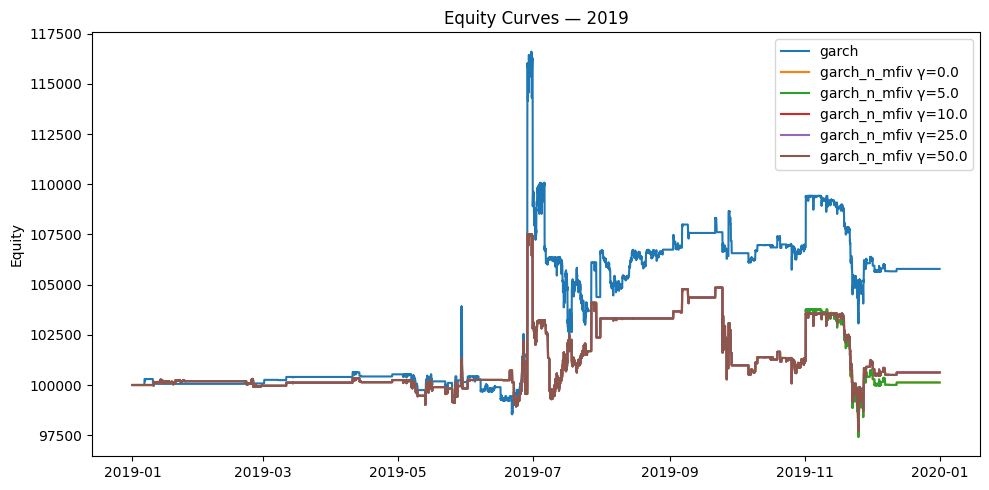

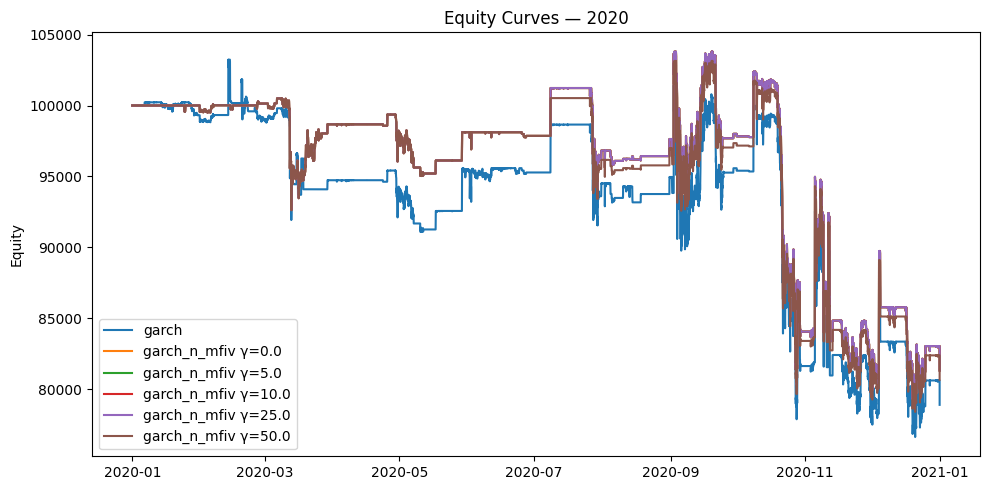

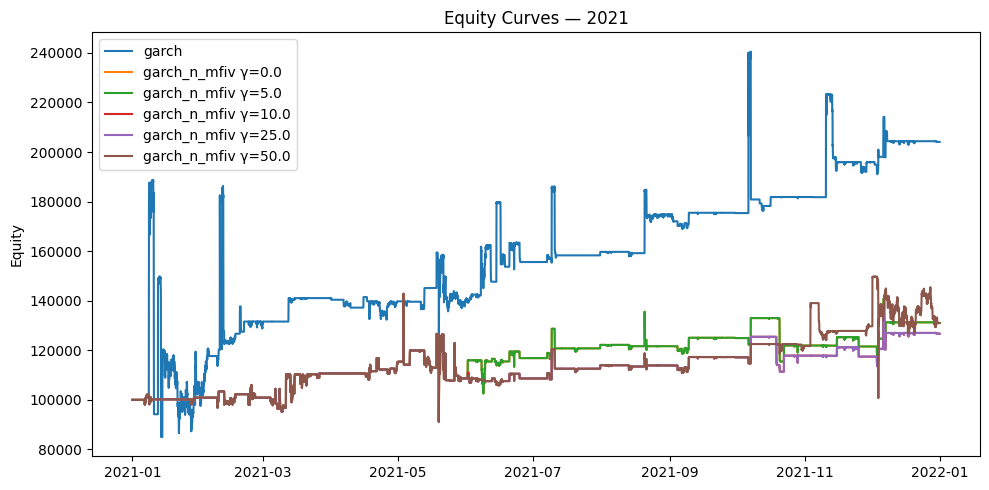

In [56]:
### TEMPORARY PLOTTING FOR STRATEGY_RESULTS_9
import matplotlib.pyplot as plt

for y in YEARS:
    plt.figure(figsize=(10, 5))

    for key, result in strategy_results.items():
        if result["year"] != y:
            continue

        equity = result["equity_curve"]

        if equity.empty:
            continue

        label = (
            result["model"]
            if result["model"] == "garch"
            else f'garch_n_mfiv γ={result["downside_gamma"]}'
        )

        plt.plot(
            equity.index,
            equity["equity"],
            label=label
        )

    plt.title(f"Equity Curves — {y}")
    plt.ylabel("Equity")
    plt.legend()
    plt.tight_layout()
    plt.show()

In [58]:
import numpy as np
import pandas as pd

rows = []

for key, result in strategy_results.items():
    if result.get("model") != "garch_n_mfiv":
        continue

    equity = result["equity_curve"]["equity"].dropna()
    tx = pd.DataFrame(result["transactions"])

    if equity.empty:
        continue

    hourly_returns = equity.pct_change().dropna()

    running_max = equity.cummax()
    drawdown = equity / running_max - 1.0

    put_entries = tx[
        (tx["action"] == "sell_to_open")
        & (tx["right"] == "P")
    ]

    rows.append({
        "year": result["year"],
        "gamma": result["downside_gamma"],
        "final_equity": equity.iloc[-1],
        "total_return": equity.iloc[-1] / equity.iloc[0] - 1.0,
        "sharpe": (
            hourly_returns.mean()
            / hourly_returns.std()
            * np.sqrt(24 * 365)
            if hourly_returns.std() > 0
            else np.nan
        ),
        "max_drawdown": drawdown.min(),
        "put_entries": len(put_entries),
        "average_put_strike": put_entries["strike"].mean(),
        "average_put_entry_price": put_entries["price"].mean()
    })

diagnostics = pd.DataFrame(rows).sort_values(
    ["year", "gamma"]
)

baseline = diagnostics[
    diagnostics["gamma"] == 0
][
    ["year", "final_equity", "sharpe", "max_drawdown"]
].rename(
    columns={
        "final_equity": "baseline_equity",
        "sharpe": "baseline_sharpe",
        "max_drawdown": "baseline_drawdown"
    }
)

diagnostics = diagnostics.merge(
    baseline,
    on="year",
    how="left"
)

diagnostics["equity_change_vs_gamma_0"] = (
    diagnostics["final_equity"]
    - diagnostics["baseline_equity"]
)

diagnostics["sharpe_change_vs_gamma_0"] = (
    diagnostics["sharpe"]
    - diagnostics["baseline_sharpe"]
)

diagnostics["drawdown_change_vs_gamma_0"] = (
    diagnostics["max_drawdown"]
    - diagnostics["baseline_drawdown"]
)

print(
    diagnostics[
        [
            "year",
            "gamma",
            "final_equity",
            "equity_change_vs_gamma_0",
            "sharpe",
            "sharpe_change_vs_gamma_0",
            "max_drawdown",
            "drawdown_change_vs_gamma_0",
            "put_entries",
            "average_put_strike",
            "average_put_entry_price"
        ]
    ].to_string(index=False)
)

 year  gamma  final_equity  equity_change_vs_gamma_0    sharpe  sharpe_change_vs_gamma_0  max_drawdown  drawdown_change_vs_gamma_0  put_entries  average_put_strike  average_put_entry_price
 2019    0.0 100126.348097                  0.000000  0.070547                  0.000000     -0.094001                    0.000000           46         8081.521739               250.608621
 2019    5.0 100126.348097                  0.000000  0.070547                  0.000000     -0.094001                    0.000000           46         8081.521739               250.608621
 2019   10.0 100623.994647                497.646550  0.110839                  0.040292     -0.091273                    0.002728           46         8070.652174               246.115703
 2019   25.0 100623.994647                497.646550  0.110839                  0.040292     -0.091273                    0.002728           46         8070.652174               246.115703
 2019   50.0 100623.994647                497.646550  0

Pulling the put strike lower does reduce downside assignment/ITM risk, but it also means:
You sell a cheaper put and collect less premium.
The farther OTM put may reduce profit in normal periods because premium income falls.
The adjustment only helps when the reduction in downside losses is larger than the premium you gave up.
Because strikes are discrete, gamma may change no strike at all, or jump suddenly to a much cheaper strike.

### continue

In [13]:
# garch: expiry_days, hold_days, lookback_hours, mean_hours used as passed
# garch_mfiv: expiry_days, hold_days, lookback_hours, mean_hours used as passed
# garch_n_mfiv: expiry_days, lookback_hours, mean_hours used as passed; hold period uses selected_horizon
# garch_mfiv_avg: expiry_days, hold_days, lookback_hours, mean_hours used as passed
# regime_switching_mfiv: expiry_days and hold_days used as passed; lookback_hours and mean_hours use selected_horizon

In [ ]:
# # strat results 02 use 260 lookback, 03 uses 20 . 04 is with no accounting errors CURRENT
# # 5 trades all strikes above upper boundary, and all strikes below lower boundary
# # 6 also trades both sides, long and short. with only 100,000
# # 7 uses selected_horizon for both strike selection and hold period computation. Uses un-sparse data. So 06 is bad, it contains 70% null values
# # 8 is to have more long positions, see CHANGED_040826
# # 9 contains gamma backtest
import pickle
with open("/Users/shah/CODE_BOOK_4/CodeCleanup_II/data_strategy_results/IS/yearly/testing/strategy_results_9.pkl", "wb") as f:
    pickle.dump(strategy_results, f)
    

In [ ]:
# ### CAN DELETE , JUST A DYNAMIC SAVE . NOT YET RUN 
# import pickle

# strategy_bundle = {
#     "version": 9,
#     "description": "Gamma tuning for garch_n_mfiv leverage-adjusted put strikes",
#     "parameter_grid": {
#         "downside_gamma": DOWNSIDE_GAMMAS
#     },
#     "results": strategy_results
# }

# with open("/Users/shah/CODE_BOOK_4/CodeCleanup_II/data_strategy_results/IS/yearly/testing/strategy_results_9.pkl", "wb") as f:
#     pickle.dump(strategy_bundle, f)

### combination 

In [15]:
# Load
import pickle 
with open("/Users/shah/CODE_BOOK_4/CodeCleanup_II/script_data/IS/outputs_by_year/outputs_by_year_05.pkl", "rb") as f:
    outputs_by_year = pickle.load(f)

In [68]:
import pickle
with open("/Users/shah/CODE_BOOK_4/CodeCleanup_II/data_strategy_results/IS/yearly/testing/strategy_results_7.pkl", "rb") as f:
    strategy_results = pickle.load(f)
    

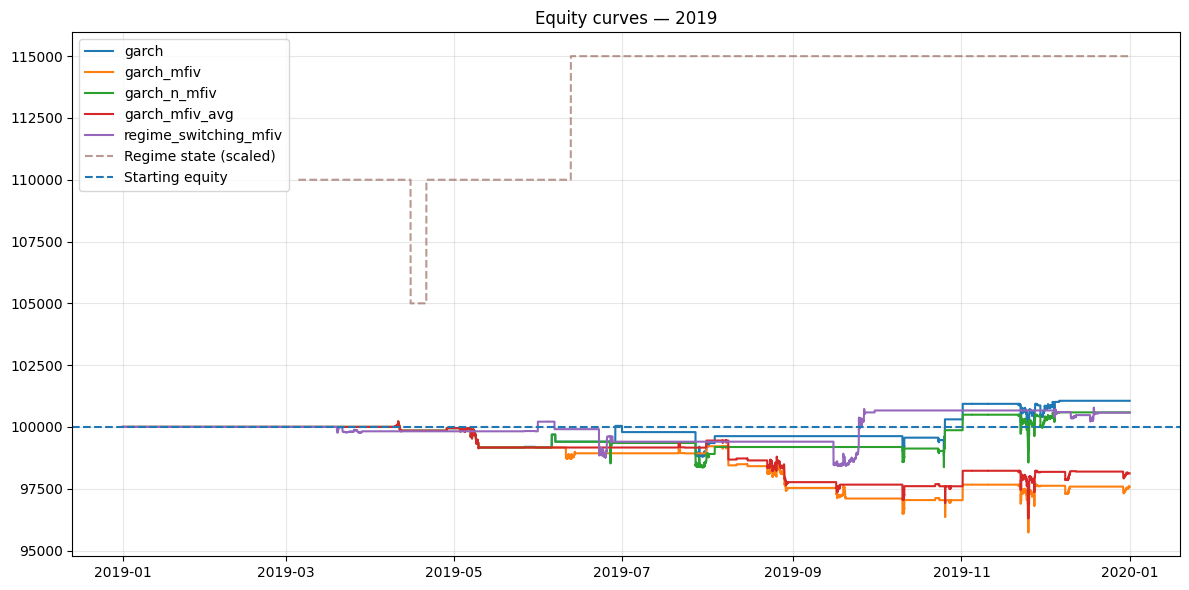

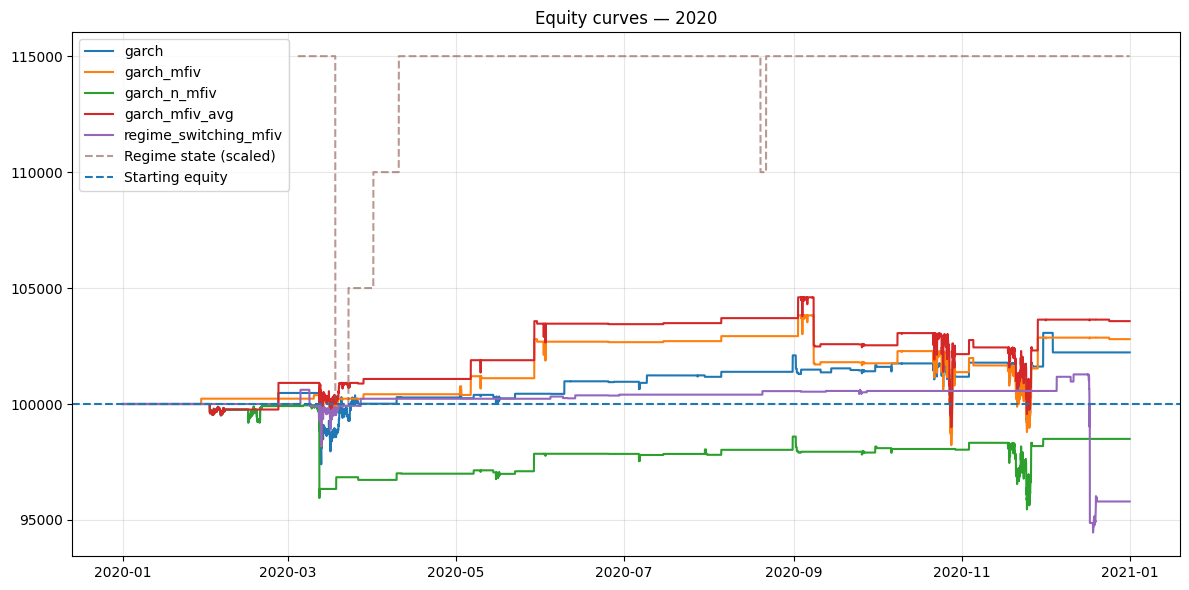

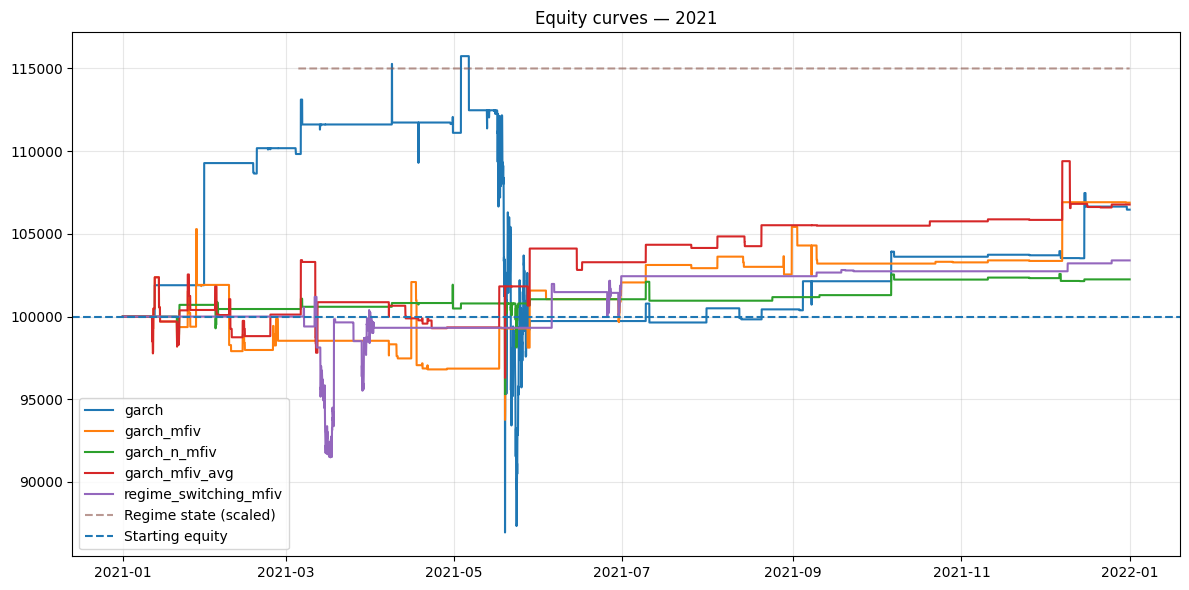

In [70]:
### PLOTTING
import matplotlib.pyplot as plt
import pandas as pd

models_to_test = [
    "garch",
    "garch_mfiv",
    "garch_n_mfiv",
    "garch_mfiv_avg",
    "regime_switching_mfiv"
]
YEARS = [2019, 2020, 2021]
QUARTERS = ["q1", "q2", "q3", "q4"]
for y in YEARS:
    plt.figure(figsize=(12, 6))

    for model in models_to_test:
        key = f"{model}_{str(y)[2:]}"

        if key not in strategy_results:
            continue

        equity_curve = strategy_results[key]["equity_curve"]

        if equity_curve.empty:
            continue

        plt.plot(
            equity_curve.index,
            equity_curve["equity"],
            label=model
        )

    regime = pd.concat(
        [
            outputs_by_year[y][q]["regime_state"]
            for q in QUARTERS
            if "regime_state" in outputs_by_year[y][q].columns
        ]
    ).sort_index()

    plt.plot(
        regime.index,
        100_000 + regime * 5_000,
        alpha=0.6,
        linestyle="--",
        label="Regime state (scaled)"
    )

    plt.axhline(
        100_000,
        linestyle="--",
        label="Starting equity"
    )

    plt.title(f"Equity curves — {y}")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

In [71]:
for model in models_to_test:
    key = f"{model}_19"
    print(key, key in strategy_results,
          None if key not in strategy_results else strategy_results[key]["equity_curve"].shape)

garch_19 True (8764, 5)
garch_mfiv_19 True (8764, 5)
garch_n_mfiv_19 True (8764, 5)
garch_mfiv_avg_19 True (8764, 5)
regime_switching_mfiv_19 True (8764, 5)


### sharpe check 

In [72]:
def annual_sharpe(equity):
    r = equity.pct_change().dropna()
    periods = pd.Timedelta(days=365.25) / r.index.to_series().diff().median()
    return np.sqrt(periods) * r.mean() / r.std()

for key, result in strategy_results.items():
    equity = result["equity_curve"]["equity"]
    print(key, annual_sharpe(equity))

garch_19 0.3645214221816856
garch_mfiv_19 -0.8834468916366436
garch_n_mfiv_19 0.21514082541146062
garch_mfiv_avg_19 -0.7052243181031886
regime_switching_mfiv_19 0.2670312729148672
garch_20 0.4215798486419526
garch_mfiv_20 0.4483072937089995
garch_n_mfiv_20 -0.27608157773714903
garch_mfiv_avg_20 0.547019965793044
regime_switching_mfiv_20 -0.704698806283541
garch_21 0.3638210954656714
garch_mfiv_21 0.5012216696799175
garch_n_mfiv_21 0.32231458087130394
garch_mfiv_avg_21 0.5553870391902475
regime_switching_mfiv_21 0.3469919750194736


### Mini Diagnostics

In [73]:
for model in models_to_test:
    key = f"{model}_19"

    eq = strategy_results[key]["equity_curve"]

    print(
        key,
        "start:", eq["equity"].iloc[0],
        "end:", eq["equity"].iloc[-1],
        "unique:", eq["equity"].nunique()
    )

garch_19 start: 100000.0 end: 101057.54746687501 unique: 843
garch_mfiv_19 start: 100000.0 end: 97571.25540118497 unique: 1088
garch_n_mfiv_19 start: 100000.0 end: 100588.87130875002 unique: 775
garch_mfiv_avg_19 start: 100000.0 end: 98118.82128249995 unique: 950
regime_switching_mfiv_19 start: 100000.0 end: 100576.57072875001 unique: 698


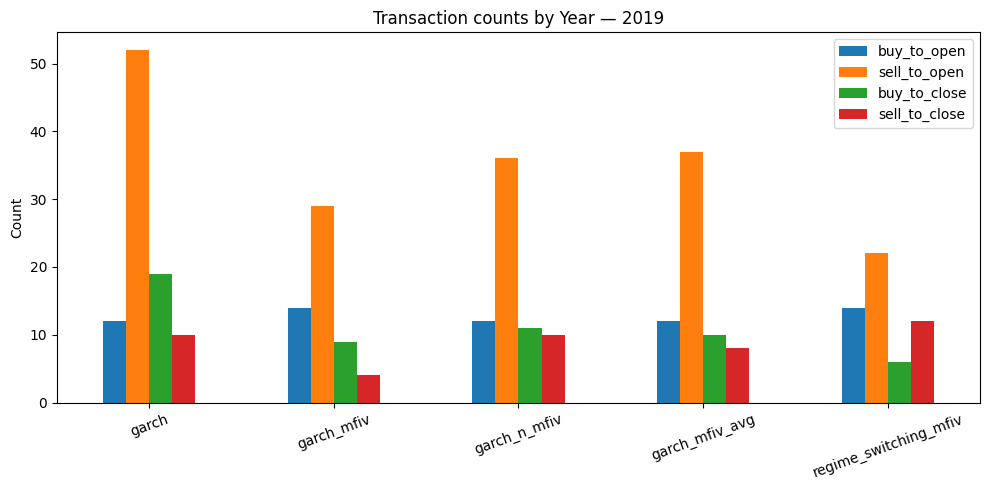

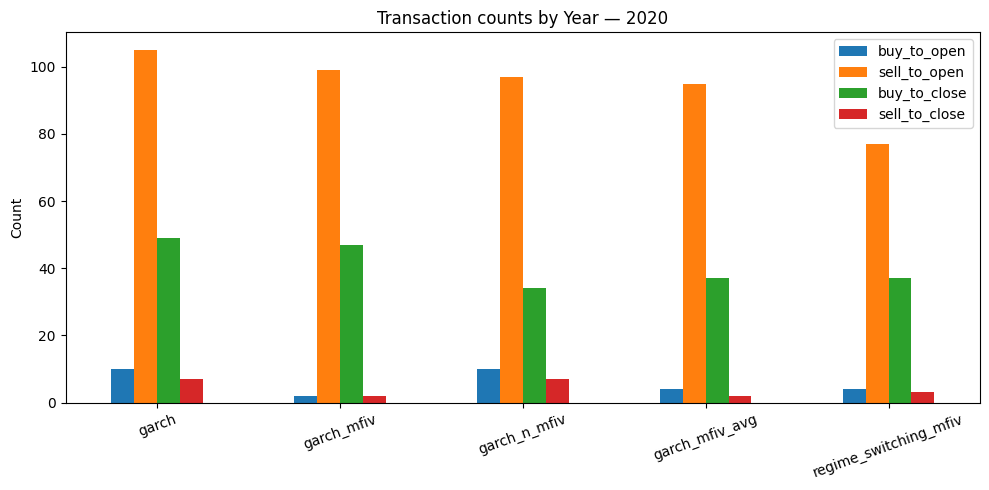

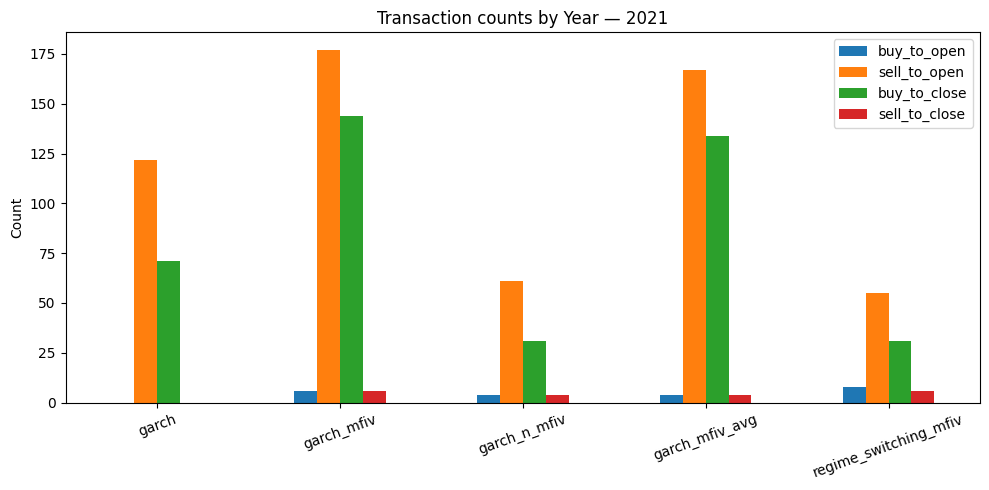

In [75]:
import matplotlib.pyplot as plt
import pandas as pd

actions = [
    "buy_to_open",
    "sell_to_open",
    "buy_to_close",
    "sell_to_close"
]

for y in YEARS:
    counts = {}

    for model in models_to_test:
        key = f"{model}_{str(y)[2:]}"
        transactions = strategy_results[key]["transactions"]

        counts[model] = [
            sum(tx["action"] == action for tx in transactions)
            for action in actions
        ]

    pd.DataFrame(
        counts,
        index=actions
    ).T.plot.bar(figsize=(10, 5))

    plt.title(f"Transaction counts by Year — {y}")
    plt.ylabel("Count")
    plt.xticks(rotation=20)
    plt.tight_layout()
    plt.show()

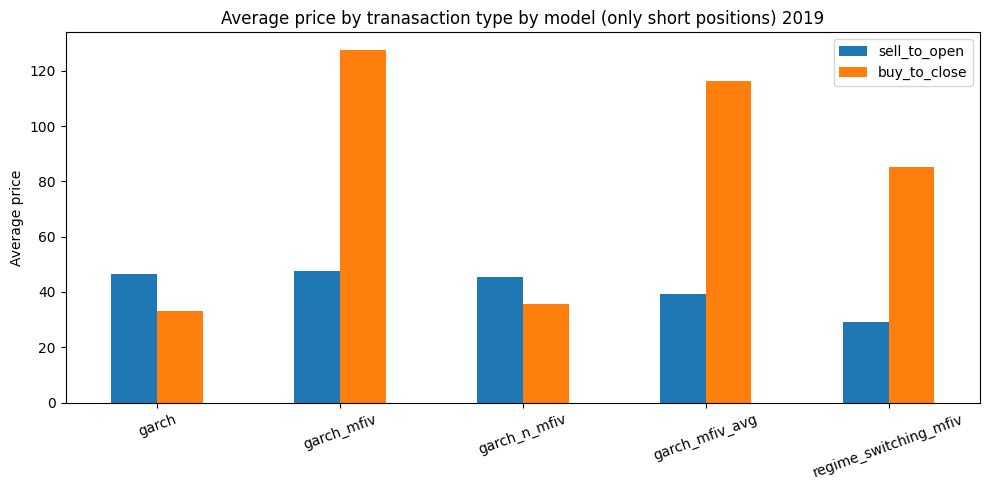

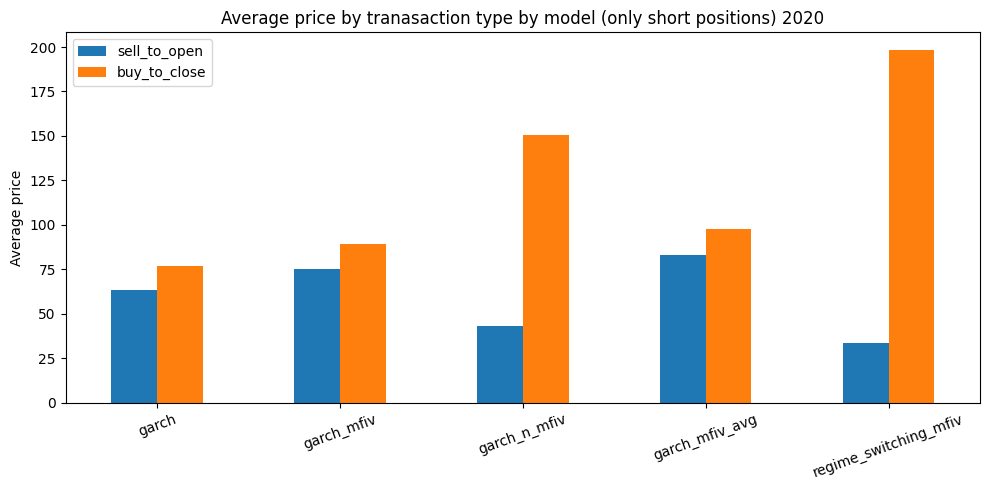

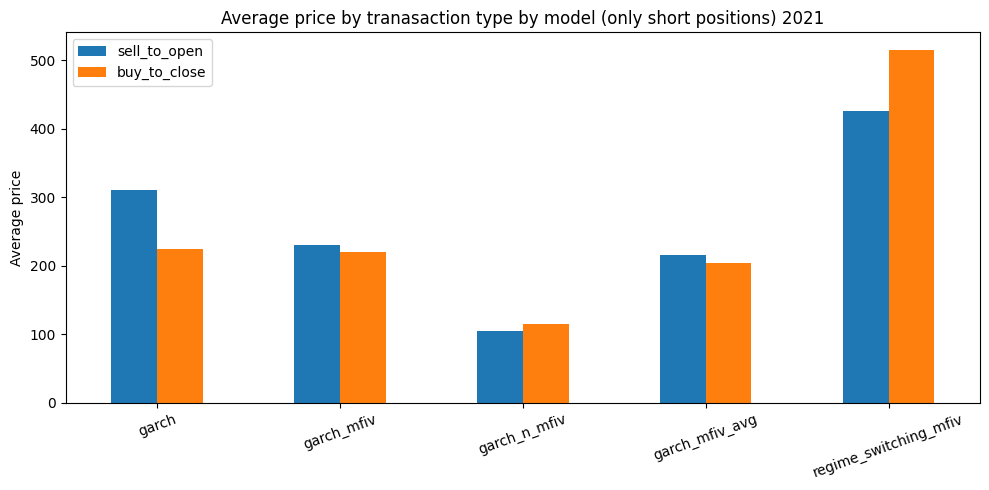

In [79]:

import matplotlib.pyplot as plt
import pandas as pd

for y in YEARS:
    rows = []

    for model in models_to_test:
        key = f"{model}_{str(y)[2:]}"
        tx = pd.DataFrame(strategy_results[key]["transactions"])

        rows.append({
            "model": model,
            "sell_to_open": tx.loc[
                tx["action"] == "sell_to_open",
                "price"
            ].mean(),
            "buy_to_close": tx.loc[
                tx["action"] == "buy_to_close",
                "price"
            ].mean()
        })

    plot_df = pd.DataFrame(rows).set_index("model")

    plot_df.plot.bar(figsize=(10, 5))
    plt.title(f"Average price by tranasaction type by model (only short positions) {y}")
    plt.ylabel("Average price")
    plt.xlabel("")
    plt.xticks(rotation=20)
    plt.tight_layout()
    plt.show()

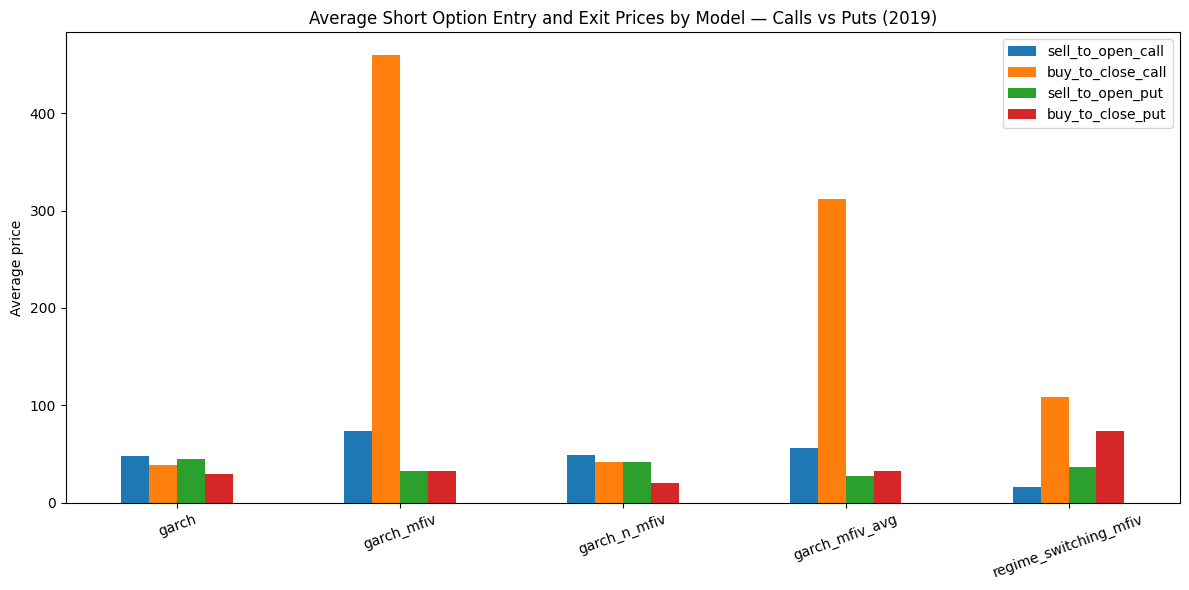

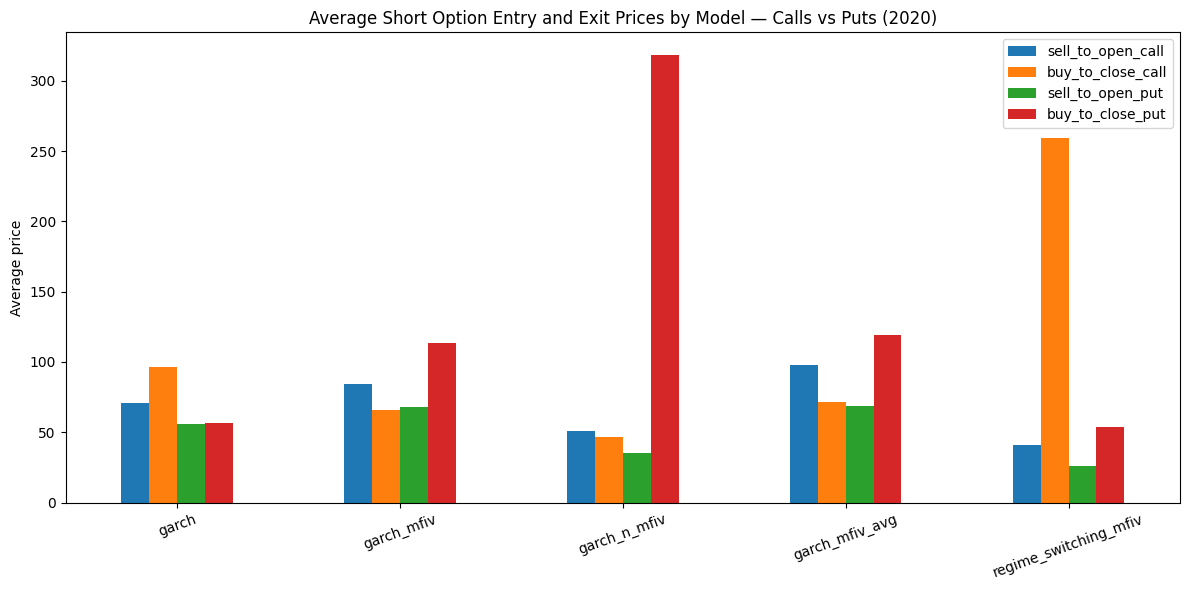

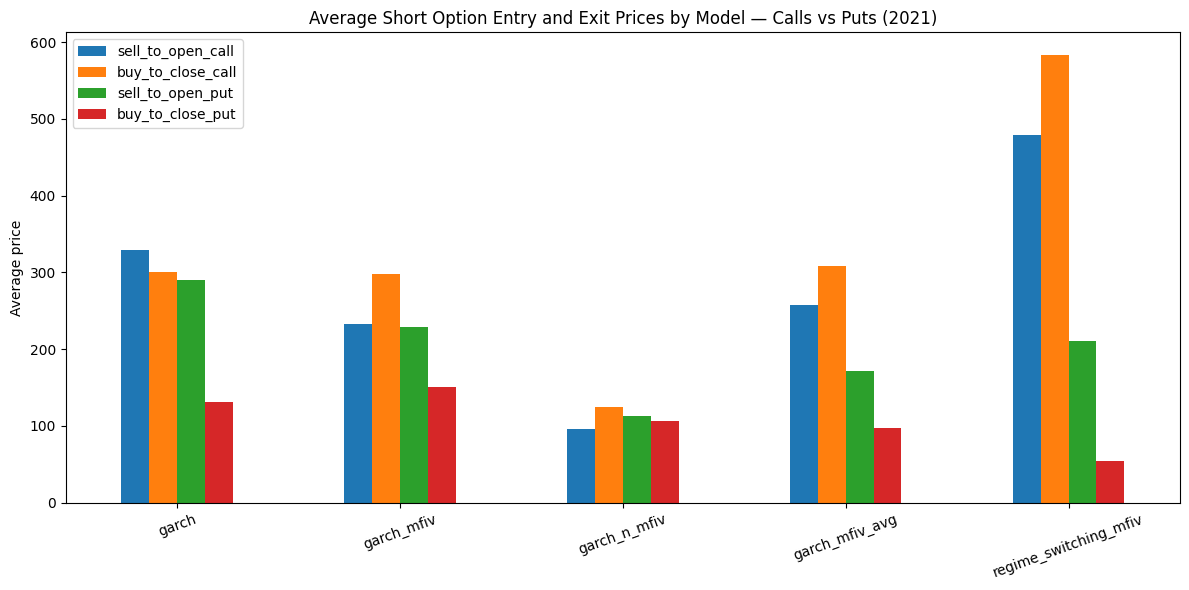

In [80]:
import matplotlib.pyplot as plt
import pandas as pd

for y in YEARS:
    rows = []

    for model in models_to_test:
        key = f"{model}_{str(y)[2:]}"
        tx = pd.DataFrame(strategy_results[key]["transactions"])

        rows.append({
            "model": model,
            "sell_to_open_call": tx.loc[
                (tx["action"] == "sell_to_open") &
                (tx["right"] == "C"),
                "price"
            ].mean(),

            "buy_to_close_call": tx.loc[
                (tx["action"] == "buy_to_close") &
                (tx["right"] == "C"),
                "price"
            ].mean(),

            "sell_to_open_put": tx.loc[
                (tx["action"] == "sell_to_open") &
                (tx["right"] == "P"),
                "price"
            ].mean(),

            "buy_to_close_put": tx.loc[
                (tx["action"] == "buy_to_close") &
                (tx["right"] == "P"),
                "price"
            ].mean()
        })

    plot_df = pd.DataFrame(rows).set_index("model")

    plot_df.plot.bar(figsize=(12, 6))

    plt.title(f"Average Short Option Entry and Exit Prices by Model — Calls vs Puts ({y})")
    plt.ylabel("Average price")
    plt.xlabel("")
    plt.xticks(rotation=20)
    plt.tight_layout()
    plt.show()

In [20]:
for model in models_to_test:
    key = f"{model}_21"

    snapshots = strategy_results[key]["snapshots"]

    print(
        key,
        "snapshots:", len(snapshots),
        "with positions:", sum(
            len(snap.get("positions", [])) > 0
            for snap in snapshots
        )
    )

garch_21 snapshots: 8764 with positions: 7213
garch_mfiv_21 snapshots: 8764 with positions: 6729
garch_n_mfiv_21 snapshots: 8764 with positions: 6809
garch_mfiv_avg_21 snapshots: 8764 with positions: 6811
regime_switching_mfiv_21 snapshots: 8764 with positions: 2179


### IMPORTANT 

In [62]:
# ## DIAG FOR 06
# ## The following must be defined for this cell 
# # strategy_results
# # YEARS
# # models_to_test
# # d_btc_raw_by_year
# import pandas as pd
# import numpy as np
# import matplotlib.pyplot as plt

# trade_periods = []

# for y in YEARS:
#     price_df = d_btc_raw_by_year[y].copy()

#     if "date_time" in price_df.columns:
#         price_df = price_df.set_index("date_time")

#     price_df.index = pd.to_datetime(
#         price_df.index,
#         utc=True
#     ).floor("h")

#     price_df = price_df.loc[
#         ~price_df.index.duplicated(keep="last")
#     ].sort_index()

#     price_col = (
#         "close"
#         if "close" in price_df.columns
#         else "Close"
#     )

#     spot = pd.to_numeric(
#         price_df[price_col],
#         errors="coerce"
#     )

#     for model in models_to_test:
#         key = f"{model}_{str(y)[2:]}"

#         if key not in strategy_results:
#             continue

#         open_trade = None

#         for snap in strategy_results[key]["snapshots"]:
#             now = pd.Timestamp(
#                 snap["time"]
#             ).floor("h")

#             positions = snap.get(
#                 "positions",
#                 []
#             )

#             currently_open = len(positions) > 0

#             if currently_open:
#                 position_df = pd.DataFrame(
#                     positions
#                 )

#                 directions = set(
#                     position_df["direction"]
#                 )

#                 if directions == {"buy"}:
#                     position_side = "long_straddle"
#                 elif directions == {"sell"}:
#                     position_side = "short_strangle"
#                 else:
#                     position_side = "mixed"

#                 if open_trade is None:
#                     open_trade = {
#                         "year": y,
#                         "model": model,
#                         "position_side": position_side,
#                         "entry_time": now,
#                         "entry_spot": spot.get(
#                             now,
#                             np.nan
#                         ),
#                         "selected_horizon": snap.get(
#                             "entry_selected_horizon"
#                         )
#                     }

#             elif open_trade is not None:
#                 open_trade["exit_time"] = now
#                 open_trade["exit_spot"] = spot.get(
#                     now,
#                     np.nan
#                 )

#                 open_trade["held_hours"] = (
#                     now
#                     - open_trade["entry_time"]
#                 ).total_seconds() / 3600

#                 open_trade["held_days"] = (
#                     open_trade["held_hours"]
#                     / 24
#                 )

#                 trade_periods.append(
#                     open_trade
#                 )

#                 open_trade = None

#         if open_trade is not None:
#             exit_time = pd.Timestamp(
#                 strategy_results[key][
#                     "snapshots"
#                 ][-1]["time"]
#             ).floor("h")

#             open_trade["exit_time"] = exit_time
#             open_trade["exit_spot"] = spot.get(
#                 exit_time,
#                 np.nan
#             )

#             open_trade["held_hours"] = (
#                 exit_time
#                 - open_trade["entry_time"]
#             ).total_seconds() / 3600

#             open_trade["held_days"] = (
#                 open_trade["held_hours"]
#                 / 24
#             )

#             trade_periods.append(
#                 open_trade
#             )

# trade_periods = pd.DataFrame(
#     trade_periods
# )

In [61]:
# # my note : 
# # snapshots is a list of dictionaries
# import pandas as pd
# import matplotlib.pyplot as plt

# y = 2021

# price = d_btc_raw_by_year[y].copy()
# if "date_time" in price.columns:
#     price = price.set_index("date_time")

# price.index = pd.to_datetime(price.index, utc=True).floor("h")
# price = price[~price.index.duplicated()].sort_index()
# spot = price["close" if "close" in price.columns else "Close"]

# fig, axes = plt.subplots(
#     len(models_to_test),
#     1,
#     figsize=(16, 4 * len(models_to_test)),
#     sharex=True
# )

# for ax, model in zip(axes, models_to_test):
#     key = f"{model}_{str(y)[2:]}"
#     snapshots = strategy_results[key]["snapshots"]

#     ax.plot(spot.index, spot, color="black", linewidth=1)

#     previous_open = False
#     entry_time = None
#     entry_positions = None

#     for snap in snapshots:
#         now = pd.Timestamp(snap["time"]).floor("h")
#         positions = snap.get("positions", [])
#         currently_open = bool(positions)

#         # New position entered
#         if currently_open and not previous_open:
#             entry_time = now
#             entry_positions = positions

#             for p in positions:
#                 is_long = p["direction"] == "buy"

#                 ax.scatter(
#                     entry_time,
#                     p["strike"],
#                     marker="^" if is_long else "v",
#                     color="red" if is_long else "green",
#                     s=35,
#                     zorder=3
#                 )

#         # Position fully closed
#         elif not currently_open and previous_open:
#             is_long = entry_positions[0]["direction"] == "buy"

#             ax.axvspan(
#                 entry_time,
#                 now,
#                 color="red" if is_long else "green",
#                 alpha=0.12
#             )

#             entry_time = None
#             entry_positions = None

#         previous_open = currently_open

#     ax.set_title(model)
#     ax.set_ylabel("BTC / strike")

# plt.xlabel("Time")
# plt.tight_layout()
# plt.show()

### My written plots

In [38]:
d_btc_raw_by_year[2021]

,timestamp,open,high,low,close,volume,cost,date_time
date_time,,,,,,,,
2020-12-31 23:00:00+00:00,1609455600000,29147.5,29147.5,29079.5,29103.5,2.658525,77350.0,2020-12-31 23:00:00+00:00
2020-12-31 23:01:00+00:00,1609455660000,29103.0,29103.0,29030.5,29033.0,3.072301,89270.0,2020-12-31 23:01:00+00:00
2020-12-31 23:02:00+00:00,1609455720000,29033.0,29033.0,28961.5,29027.5,29.551303,857070.0,2020-12-31 23:02:00+00:00
2020-12-31 23:03:00+00:00,1609455780000,29028.5,29049.5,29023.0,29023.5,6.543179,189970.0,2020-12-31 23:03:00+00:00
2020-12-31 23:04:00+00:00,1609455840000,29028.5,29086.0,29028.5,29086.0,11.856840,344420.0,2020-12-31 23:04:00+00:00
...,...,...,...,...,...,...,...,...
2022-01-01 22:55:00+00:00,1641077700000,47485.5,47485.5,47449.0,47471.0,1.546878,73430.0,2022-01-01 22:55:00+00:00
2022-01-01 22:56:00+00:00,1641077760000,47447.0,47447.0,47447.0,47447.0,0.031403,1490.0,2022-01-01 22:56:00+00:00
2022-01-01 22:57:00+00:00,1641077820000,47465.0,47465.0,47465.0,47465.0,0.025914,1230.0,2022-01-01 22:57:00+00:00


In [39]:
for snap in strategy_results[key]["snapshots"]:
    if snap["positions"]:
        print(snap["positions"][0])
        break

{'symbol': 'BTC-26MAR21-60000-C', 'strike': 60000.0, 'expiry': Timestamp('2021-03-26 00:00:00+0000', tz='UTC'), 'right': 'C', 'direction': 'sell', 'entry_price': 1561.6001999999999}


In [59]:
# import pandas as pd
# import plotly.graph_objects as go

# model = "garch_n_mfiv"

# for y in YEARS:
#     key = f"{model}_{str(y)[2:]}"
#     snapshots = strategy_results[key]["snapshots"]

#     price_df = d_btc_raw_by_year[y].copy()
#     price_df = price_df.loc[ ~price_df.index.duplicated(keep="first") ].sort_index()

#     spot = pd.to_numeric(price_df["close"], errors="coerce")

#     fig = go.Figure()

#     fig.add_trace(go.Scatter( x=spot.index, y=spot, mode="lines", name="Spot"))

#     previous_open = False
#     entry_time = None
#     entry_positions = []

#     for snap in snapshots:
#         now = pd.Timestamp(snap["time"]).floor("h")
#         positions = snap.get("positions", [])
#         currently_open = bool(positions)

#         if currently_open and not previous_open:
#             entry_time = now
#             entry_positions = positions.copy()

#         if not currently_open and previous_open:
#             exit_time = now

#             for position in entry_positions:
#                 strike = position["strike"]
#                 fig.add_trace(
#                     go.Scatter(
#                         x=[entry_time],
#                         y=[strike],
#                         mode="markers",
#                         marker={"size": 6},
#                         name=f'{position["right"]} | {position["direction"]}',
#                         showlegend=False
#                     )
#                 )

#                 fig.add_trace(
#                     go.Scatter(
#                         x=[entry_time, exit_time],
#                         y=[strike, strike],
#                         mode="lines",
#                         line={"dash": "dot"},
#                         name=position["right"],
#                         showlegend=False
#                     )
#                 )
#             entry_time = None
#             entry_positions = []

#         previous_open = currently_open

#     fig.update_layout(
#         title=f"{model} — {y}",
#         xaxis_title="Time",
#         yaxis_title="Spot / Strike",
#         hovermode="closest"
#     )

#     fig.update_xaxes(rangeslider_visible=True)

#     fig.show()


In [60]:
# import pandas as pd
# import plotly.graph_objects as go

# model = "garch"

# for y in YEARS:
#     key = f"{model}_{str(y)[2:]}"
#     snapshots = strategy_results[key]["snapshots"]

#     price_df = d_btc_raw_by_year[y].copy()
#     price_df = price_df.loc[
#         ~price_df.index.duplicated(keep="first")
#     ].sort_index()

#     spot = pd.to_numeric(price_df["close"], errors="coerce")

#     fig = go.Figure()

#     fig.add_trace(
#         go.Scatter(
#             x=spot.index,
#             y=spot,
#             mode="lines",
#             name="Spot"
#         )
#     )

#     previous_open = False
#     entry_time = None
#     entry_positions = []

#     for snap in snapshots:
#         now = pd.Timestamp(snap["time"]).floor("h")
#         positions = snap.get("positions", [])
#         currently_open = bool(positions)

#         if currently_open and not previous_open:
#             entry_time = now
#             entry_positions = positions.copy()

#         if not currently_open and previous_open:
#             exit_time = now

#             for position in entry_positions:
#                 strike = position["strike"]
#                 fig.add_trace(
#                     go.Scatter(
#                         x=[entry_time],
#                         y=[strike],
#                         mode="markers",
#                         marker={"size": 6},
#                         name=position["right"],
#                         showlegend=False
#                     )
#                 )

#                 fig.add_trace(
#                     go.Scatter(
#                         x=[entry_time, exit_time],
#                         y=[strike, strike],
#                         mode="lines",
#                         line={"dash": "dot"},
#                         name=position["right"],
#                         showlegend=False
#                     )
#                 )
#             entry_time = None
#             entry_positions = []

#         previous_open = currently_open

#     fig.update_layout(
#         title=f"{model} — {y}",
#         xaxis_title="Time",
#         yaxis_title="Spot / Strike",
#         hovermode="closest"
#     )

#     fig.update_xaxes(rangeslider_visible=True)

#     fig.show()

In [13]:
strategy_results["garch_n_mfiv_21"]["orders"]

[{'time': Timestamp('2021-01-07 12:00:00+0000', tz='UTC'),
  'symbol': 'BTC-29JAN21-40000-C',
  'strike': 40000.0,
  'expiry': Timestamp('2021-01-29 00:00:00+0000', tz='UTC'),
  'right': 'C',
  'spot_entry': np.float64(37952.5),
  'side': 'short',
  'qty': 1,
  'entry_price': 4056.2452649999996},
 {'time': Timestamp('2021-01-07 12:00:00+0000', tz='UTC'),
  'symbol': 'BTC-29JAN21-40000-C',
  'strike': 40000.0,
  'expiry': Timestamp('2021-01-29 00:00:00+0000', tz='UTC'),
  'right': 'C',
  'spot_entry': np.float64(37952.5),
  'side': 'short',
  'qty': 1,
  'entry_price': 3999.2882999999997},
 {'time': Timestamp('2021-01-07 12:00:00+0000', tz='UTC'),
  'symbol': 'BTC-29JAN21-40000-C',
  'strike': 40000.0,
  'expiry': Timestamp('2021-01-29 00:00:00+0000', tz='UTC'),
  'right': 'C',
  'spot_entry': np.float64(37952.5),
  'side': 'short',
  'qty': 1,
  'entry_price': 3995.7371999999996},
 {'time': Timestamp('2021-01-07 12:00:00+0000', tz='UTC'),
  'symbol': 'BTC-29JAN21-40000-C',
  'strike': 